# Tema : Modelos ARIMA
![](src/img/logo_utb.png){width=40%}
![](src/img/logo_etd.png){width=40%}
- **Profesor:**
- **Fernando Salcedo Mejía, Eco Msc.**
- Programa de Ciencias de Datos | Escuela de transformación digital.
- 2026-1

## Ejercicio 1. Pronostico del PIB de Colombia.

- Usando los datos del Banco Mundial, estime un modelo ARIMA válido acorde a la teoría entre 1960-2023. Finalmente, realice el pronostico del PIB de Colombia para los próximos 5 años.

## Librerías necesarias

In [1]:
# Instalar todas las librerias necesarias previamente desde r-requirements.txt

suppressPackageStartupMessages({
  # Datos
  library(tidyverse)
  library(wbstats)     # Datos del Banco Mundial

  # Modelos de tiempo
  library(fable)       # Modelos ETS, ARIMA, etc.
  library(feasts)      # ACF, PACF, descomposición y características de series
  library(tsibble)     # Estructura de datos para series de tiempo
  library(ggtime)      # Visualización

  # Estadísticos
  library(tseries)     # Pruebas ADF y KPSS, Jarque-Bera
  library(moments)     # Asimetría y curtosis
  library(patchwork)   # Combinar gráficos
})

# tamaño de los graficos
options(repr.plot.width = 8,
        repr.plot.height = 6,
        repr.plot.res = 300,
        repr.plot.pointsize = 14)

set_theme(theme_bw())

## Descargar los datos del Banco Mundial

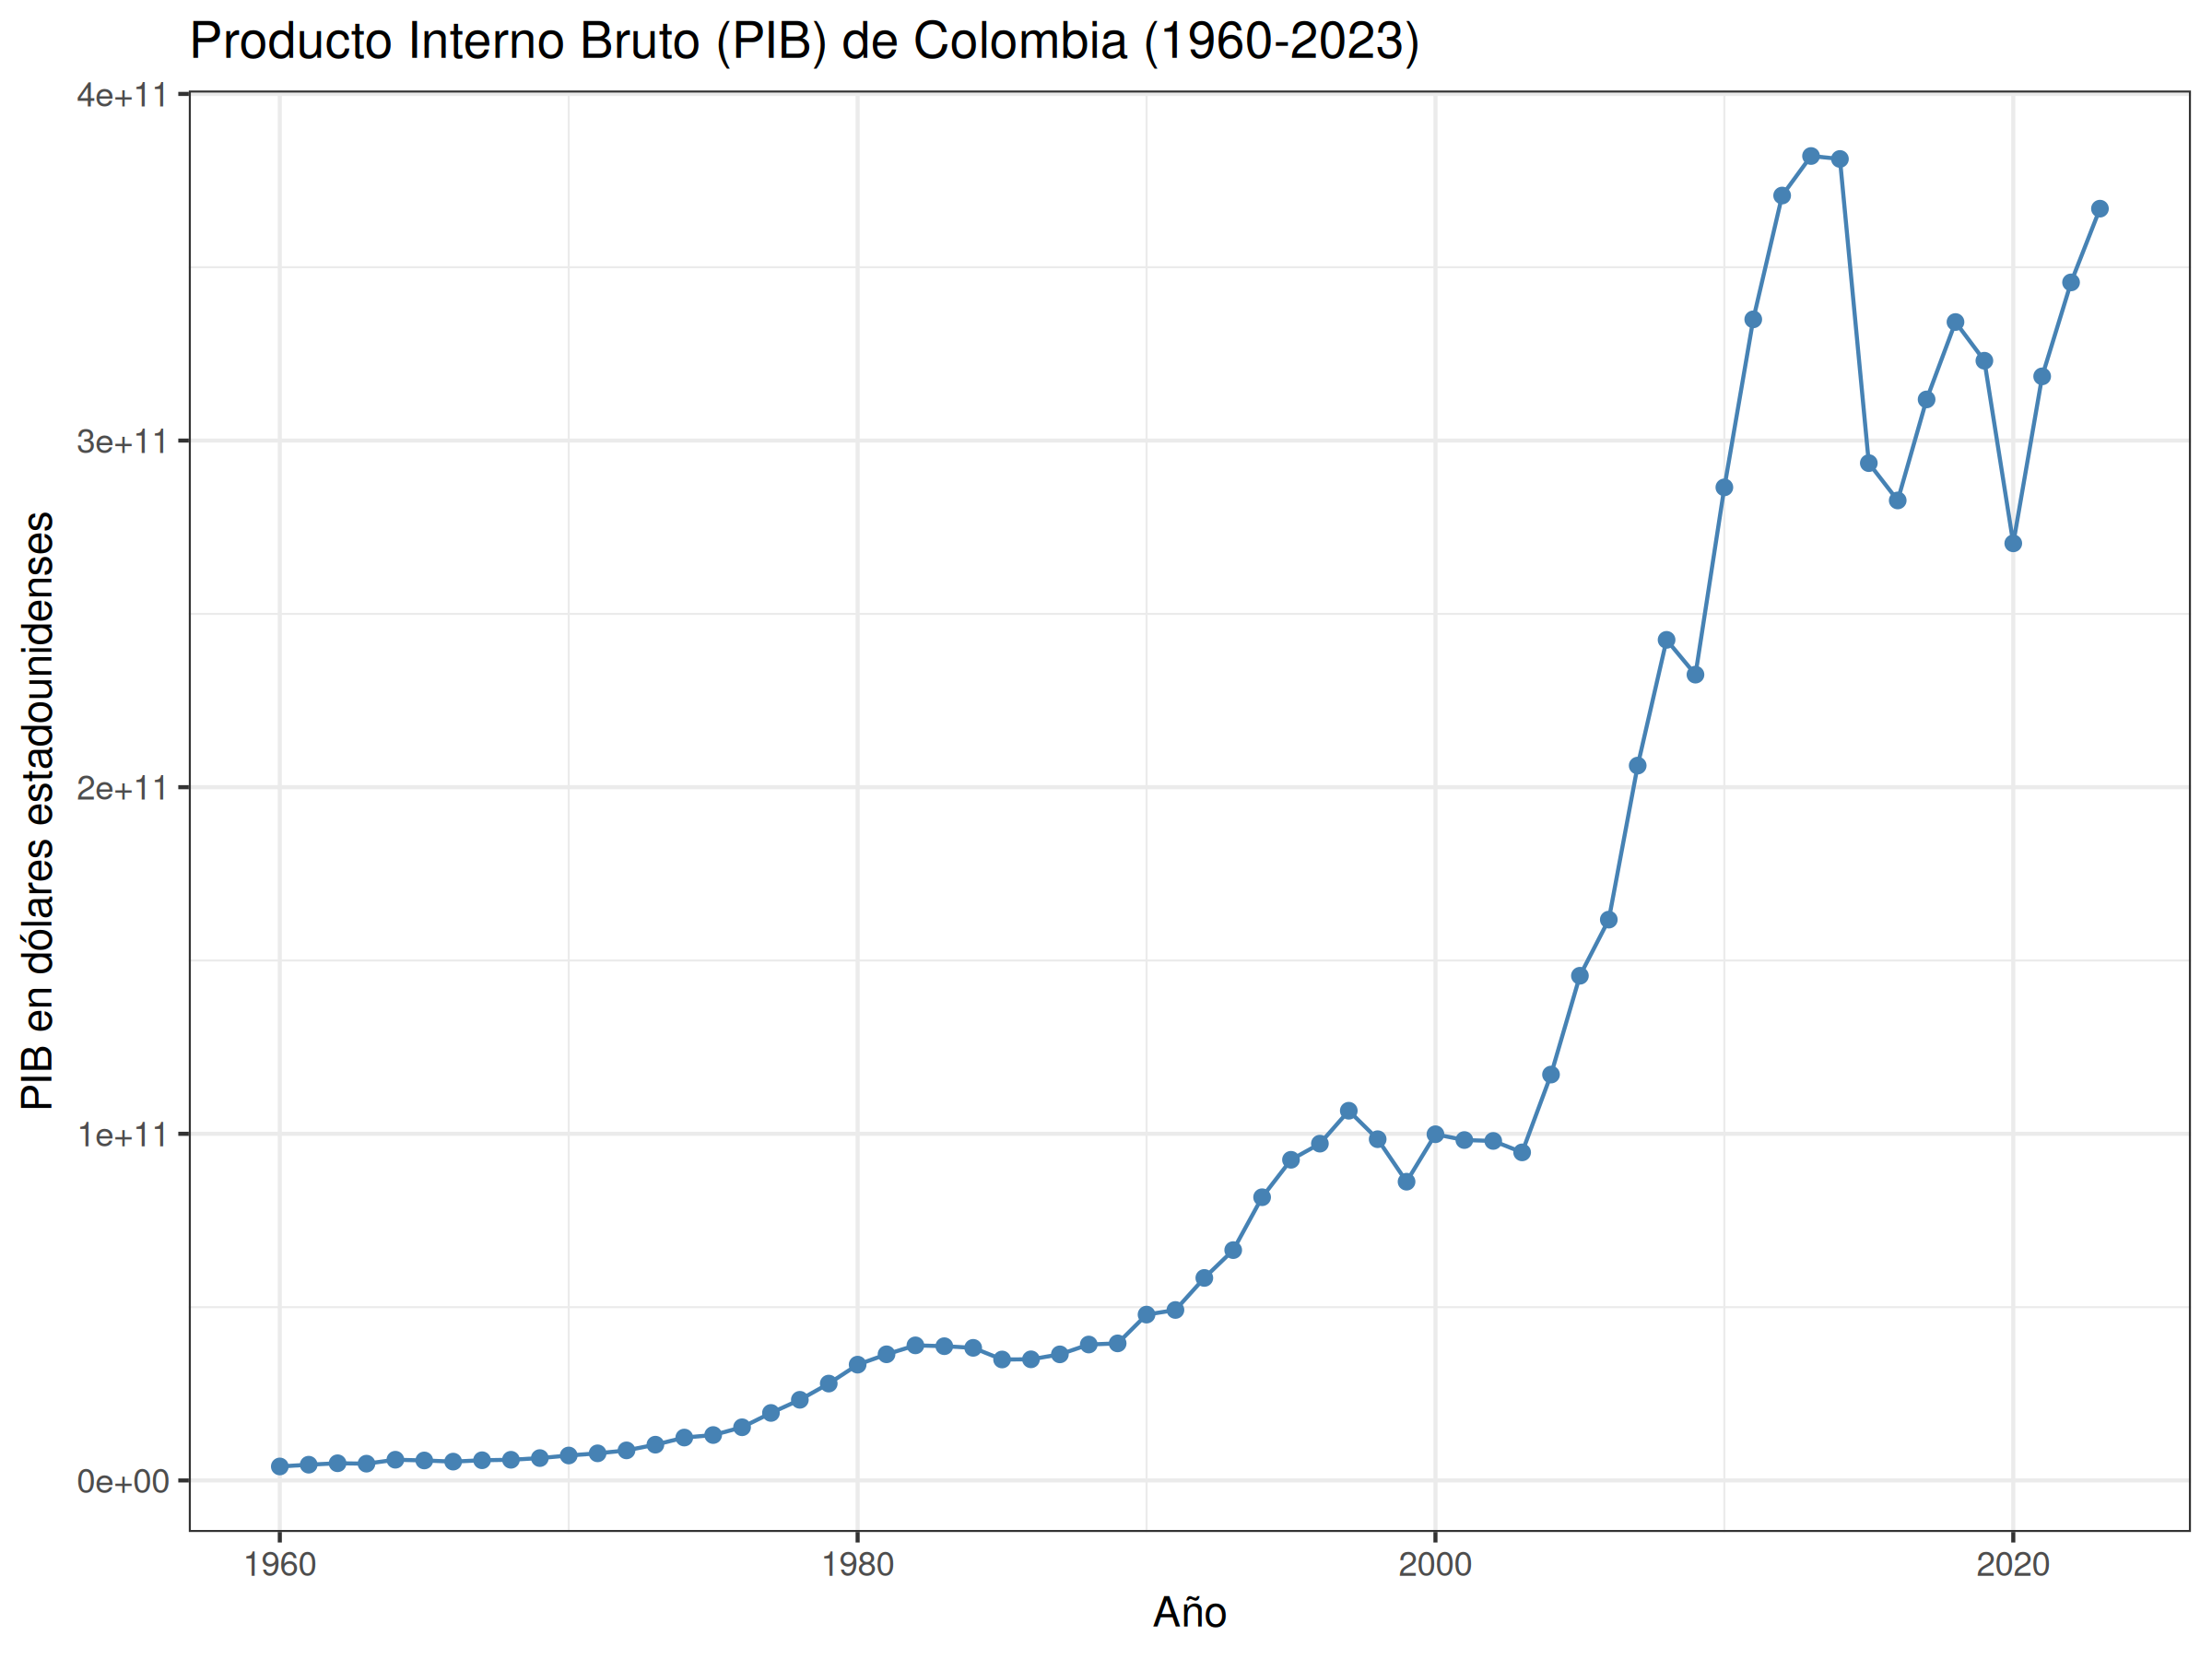

In [2]:
# PIB de Colombia en dólares corrientes (NY.GDP.MKTP.CD)
data_wb <- wb_data(indicator = "NY.GDP.MKTP.CD", country = "COL",
                   start_date = 1960, end_date = 2023)

pib_col <- data_wb |>
  select(year = date, pib = NY.GDP.MKTP.CD) |>
  drop_na(pib) |>
  as_tsibble(index = year)

# Gráfico de la serie
pib_col |>
  autoplot(pib, colour = "steelblue") +
  geom_point(colour = "steelblue") +
  labs(
    title = "Producto Interno Bruto (PIB) de Colombia (1960-2023)",
    x = "Año", y = "PIB en dólares estadounidenses"
  )

## Verificar estacionaridad de la serie original

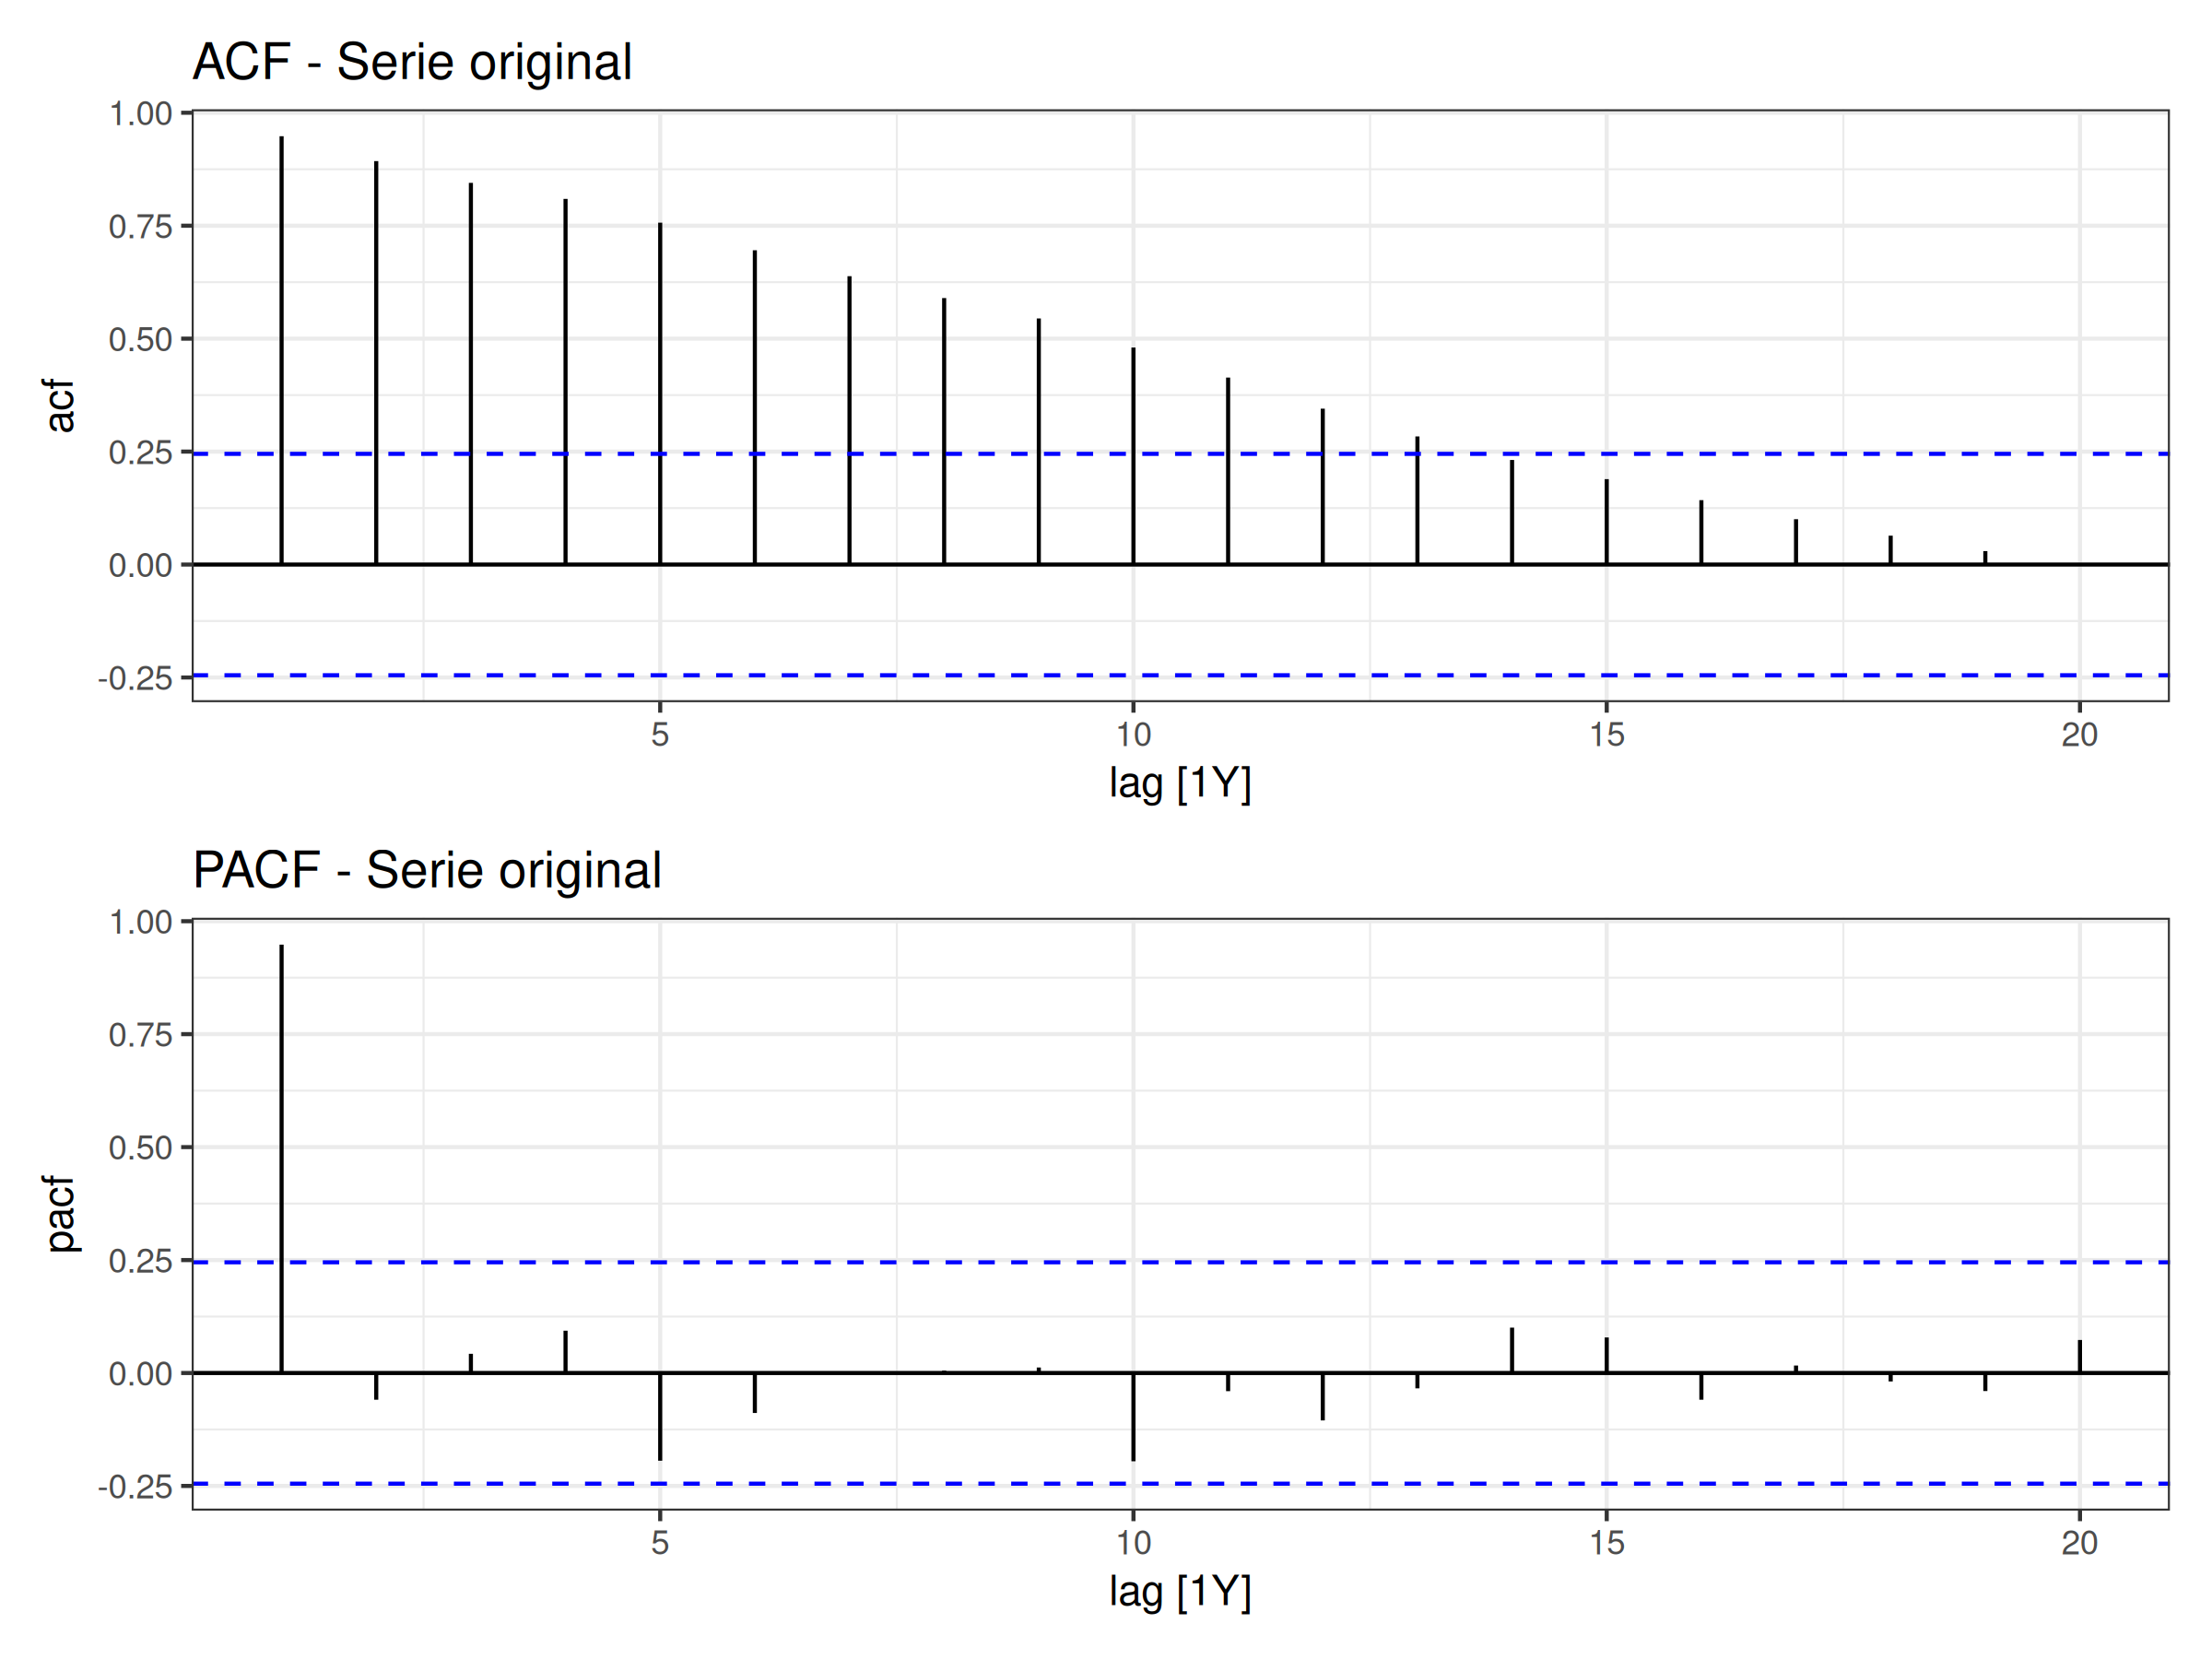

In [3]:
# Graficar la funcion de ACF y PACF
graficar_autocorrelacion <- function(datos, variable, titulo, max_lag = 20) {
  p1 <- datos |>
    ACF({{ variable }}, lag_max = max_lag) |>
    autoplot() +
    labs(title = paste("ACF -", titulo))
  p2 <- datos |>
    PACF({{ variable }}, lag_max = max_lag) |>
    autoplot() +
    labs(title = paste("PACF -", titulo))
  p1 / p2
}

graficar_autocorrelacion(pib_col, pib, titulo = "Serie original")

In [4]:
test_autocorrelacion <- function(datos, n_lags = 20) {
  datos <- as.numeric(na.omit(datos))

  # Ljung-Box (Prueba global): se toma el rezago con menor p-valor
  lb_test <- map_dfr(1:n_lags, \(k) {
    lb <- Box.test(datos, lag = k, type = "Ljung-Box")
    tibble(lag = k, lb_stat = unname(lb$statistic), lb_pvalue = lb$p.value)
  })
  lb_min <- lb_test |> slice_min(lb_pvalue, n = 1, with_ties = FALSE)

  # Durbin-Watson (Autocorrelación de primer orden)
  dw_stat <- sum(diff(datos)^2) / sum(datos^2)

  # Tabla de resultados
  tibble(
    Test        = c("Durbin-Watson", paste0("Ljung-Box (hasta lag ", n_lags, ")")),
    Estadistico = round(c(dw_stat, lb_min$lb_stat), 4),
    `P-valor`   = c(NA, round(lb_min$lb_pvalue, 4)),
    Conclusion  = c(
      case_when(
        dw_stat > 1.5 & dw_stat < 2.5 ~ "Sin autocorrelación",
        dw_stat <= 1.5                ~ "Autocorrelación positiva",
        TRUE                          ~ "Autocorrelación negativa"
      ),
      if_else(lb_min$lb_pvalue > 0.05, "Sin autocorrelación", "Autocorrelación detectada")
    )
  )
}

test_autocorrelacion(pib_col$pib, n_lags = 20)

Test,Estadistico,P-valor,Conclusion
<chr>,<dbl>,<dbl>,<chr>
Durbin-Watson,0.0152,NA,Autocorrelación positiva
Ljung-Box (hasta lag 20),114.5863,0,Autocorrelación detectada


In [5]:
test_estacionariedad <- function(datos) {
  datos <- as.numeric(na.omit(datos))
  # Augmented Dickey-Fuller (H0: la serie tiene raíz unitaria)
  adf_result  <- suppressWarnings(adf.test(datos))
  # KPSS (H0: la serie es estacionaria en nivel)
  kpss_result <- suppressWarnings(kpss.test(datos, null = "Level"))

  # Tabla de resultados
  tibble(
    Test         = c("Prueba Augmented Dickey-Fuller (ADF)", "Prueba KPSS"),
    Estadistico  = round(c(adf_result$statistic, kpss_result$statistic), 4),
    `P-valor`    = round(c(adf_result$p.value, kpss_result$p.value), 4),
    Estacionario = c(if_else(adf_result$p.value < 0.05, "Sí", "No"),
                     if_else(kpss_result$p.value < 0.05, "No", "Sí"))
  )
}

test_estacionariedad(pib_col$pib)

Test,Estadistico,P-valor,Estacionario
<chr>,<dbl>,<dbl>,<chr>
Prueba Augmented Dickey-Fuller (ADF),-1.7590,0.6726,No
Prueba KPSS,1.4446,0.0100,No


**Interpretación**

- El ACF decae muy lentamente y el PACF tiene un único pico en el rezago 1: patrón típico de una serie con raíz unitaria.
- Ljung-Box y Durbin-Watson (≈ 0) confirman una autocorrelación muy fuerte.
- La prueba ADF no rechaza la hipótesis de raíz unitaria y la KPSS rechaza la estacionariedad: la serie en niveles **no es estacionaria**.

## Integración de la serie para estacionaridad

- Para integrar una serie con el fin de estabilizar la media y la varianza sacamos su primera diferencia

1. $E[Y_t] = \mu$ (constante) $\forall t$
2. $Var(Y_t) = \sigma^2$ (constante) $\forall t$
3. $Cov(Y_t, Y_{t+k}) = \gamma_k$ (solo depende del rezago $k$)

$$
\Delta y_t = y_t - y_{t-1}
$$

## Transformaciones usuales en las series económicas

- Es usual transformar la series económicas en términos de crecimiento porcentual aplicando logaritmos y posterior tomar su primera diferencia que es equivalente a incremento porcentual.
- Como vimos en la transformación de Box-Cox (λ=0), el logaritmo ayuda a linealizar funciones exponenciales y varianza creciente.

$$
\Delta \log{y_t} = \log{y_t} - \log{y_{t-1}} = \log{\frac{y_t}{y_{t-1}}} \sim \%\Delta y_t
$$

In [6]:
# Mejor lambda de la transformación de Box-Cox (método de Guerrero)
lambda_boxcox <- pib_col |>
  features(pib, features = guerrero) |>
  pull(lambda_guerrero)

cat("Lambda Box-Cox:", lambda_boxcox, "\n")

Lambda Box-Cox: -0.1006906 


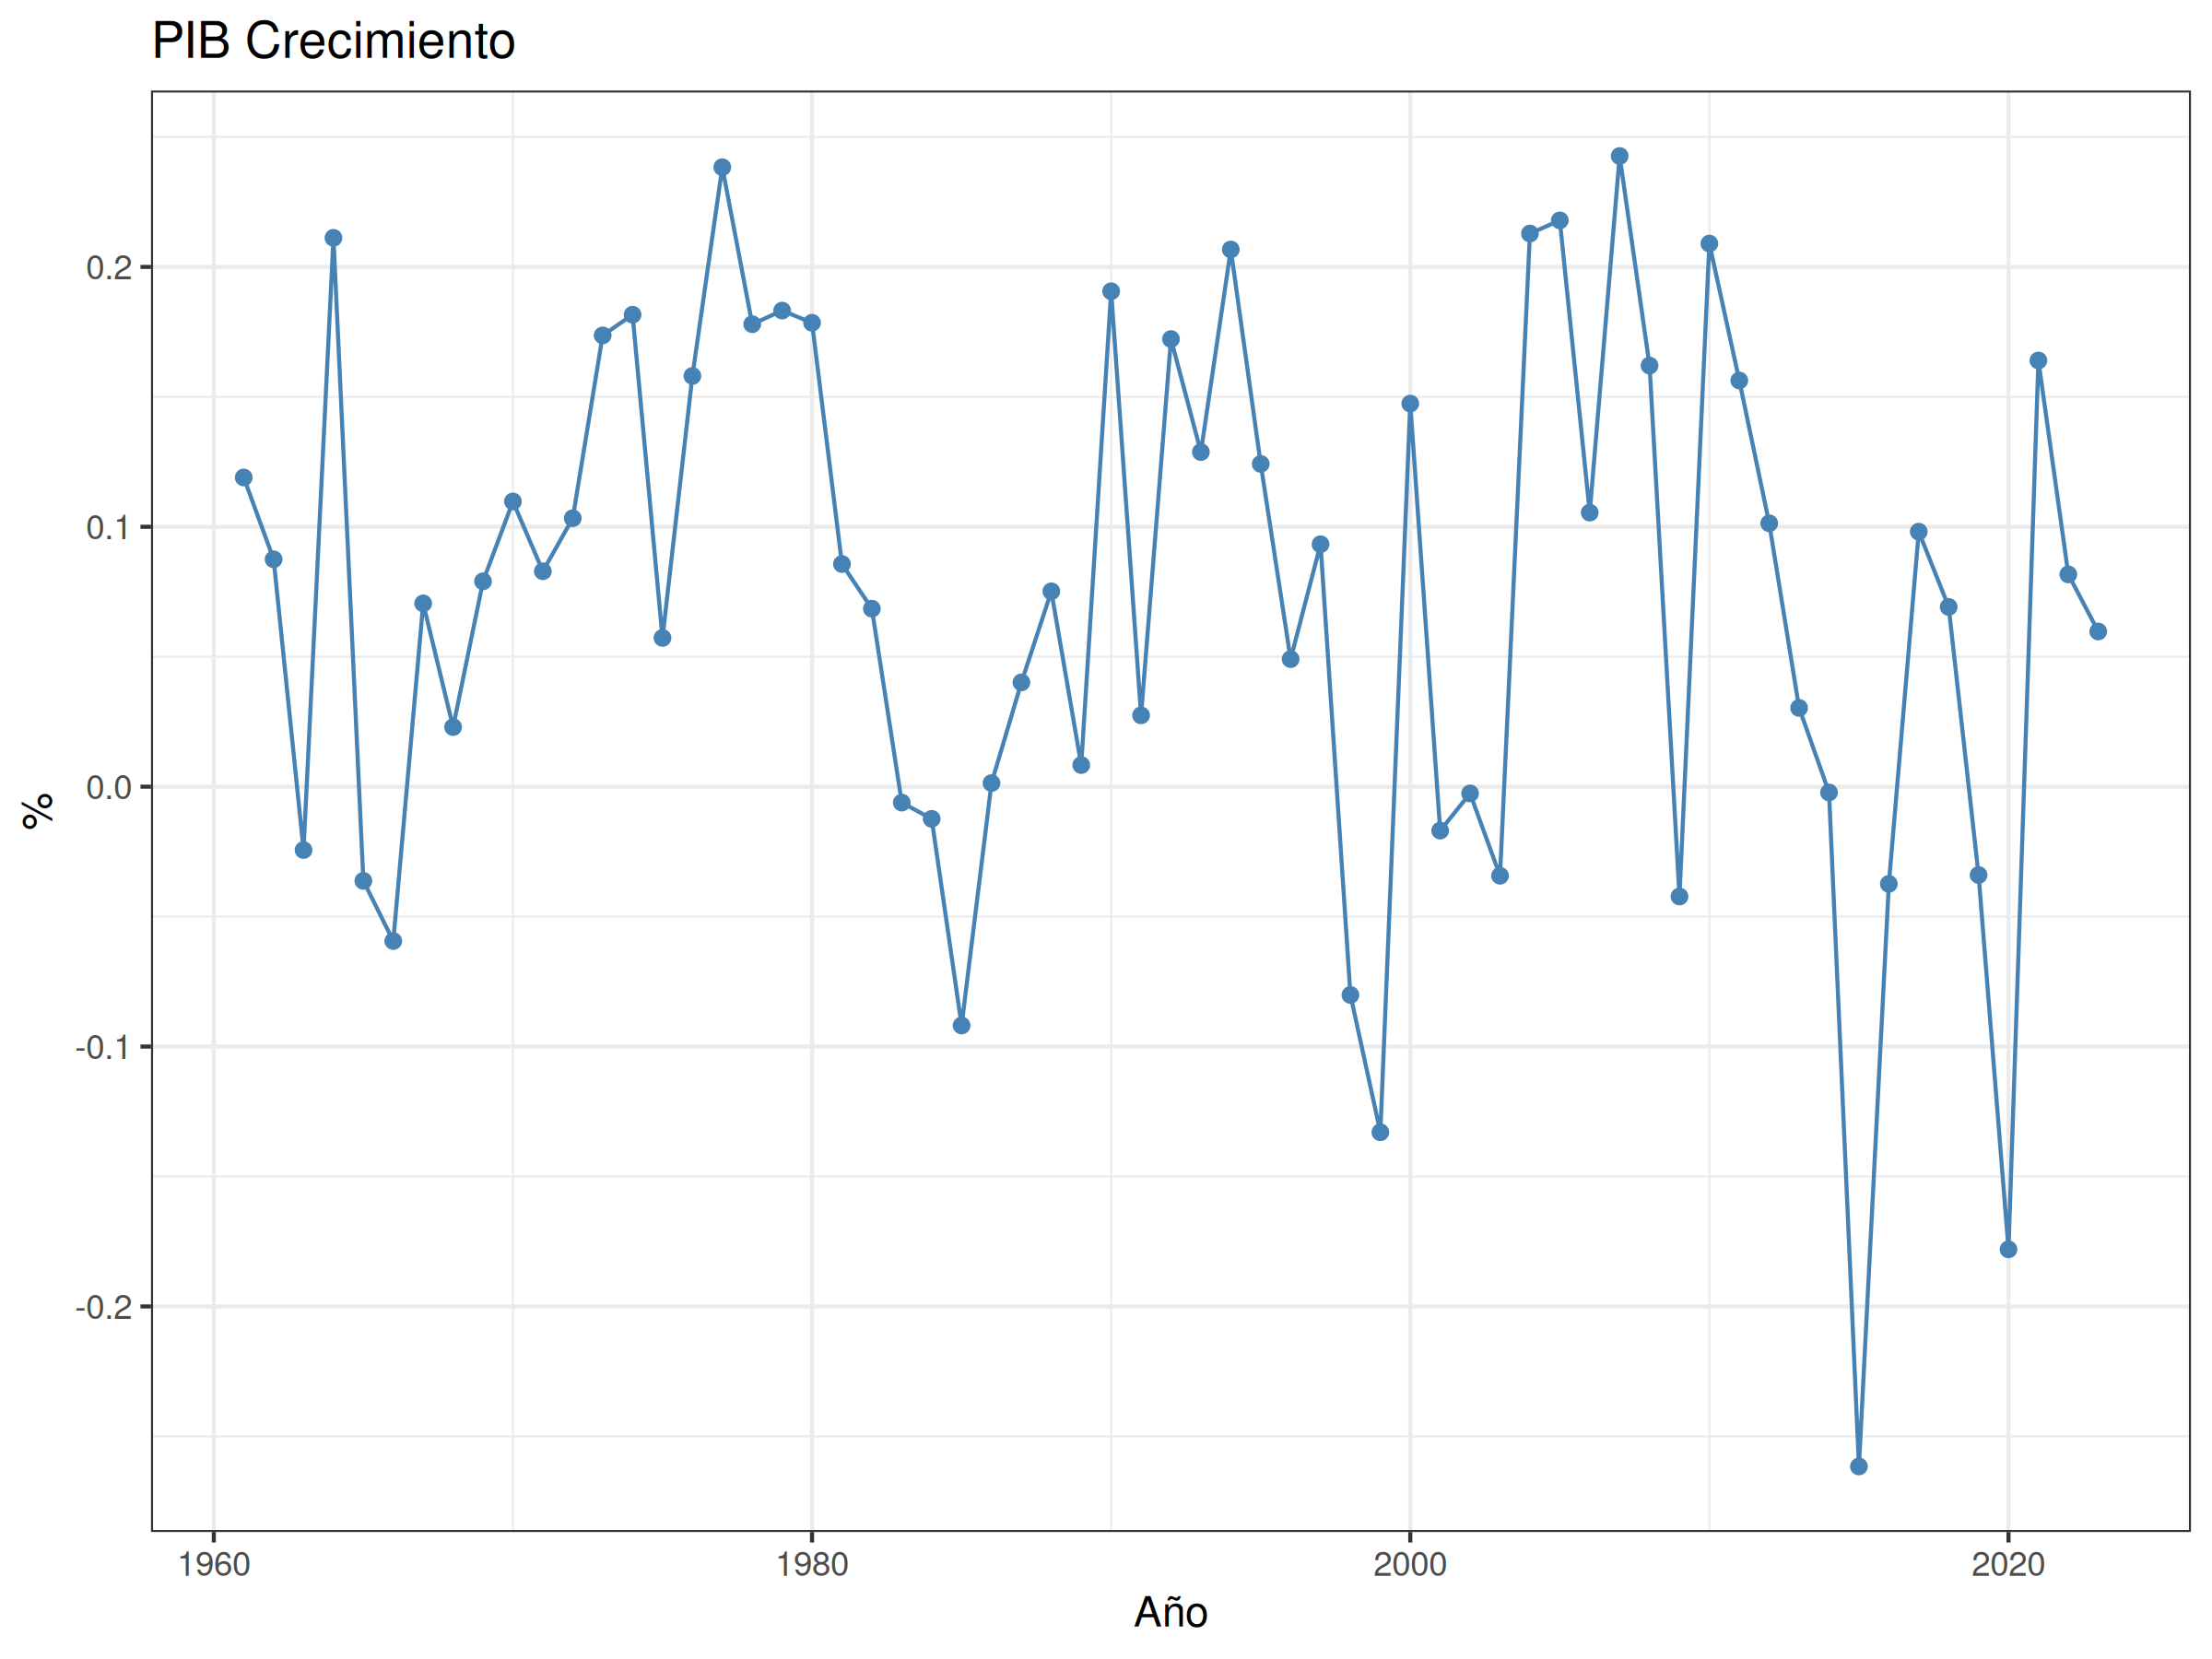

In [7]:
# Primera diferencia de la serie (integrada de orden 1)
# Logaritmo y primera diferencia: transforma la serie en tasas de crecimiento
pib_col <- pib_col |>
  mutate(
    pib_diff    = difference(pib),
    crecimiento = difference(log(pib))
  )

pib_col |>
  filter(!is.na(crecimiento)) |>
  autoplot(crecimiento, colour = "steelblue") +
  geom_point(colour = "steelblue") +
  labs(title = "PIB Crecimiento", x = "Año", y = "%")

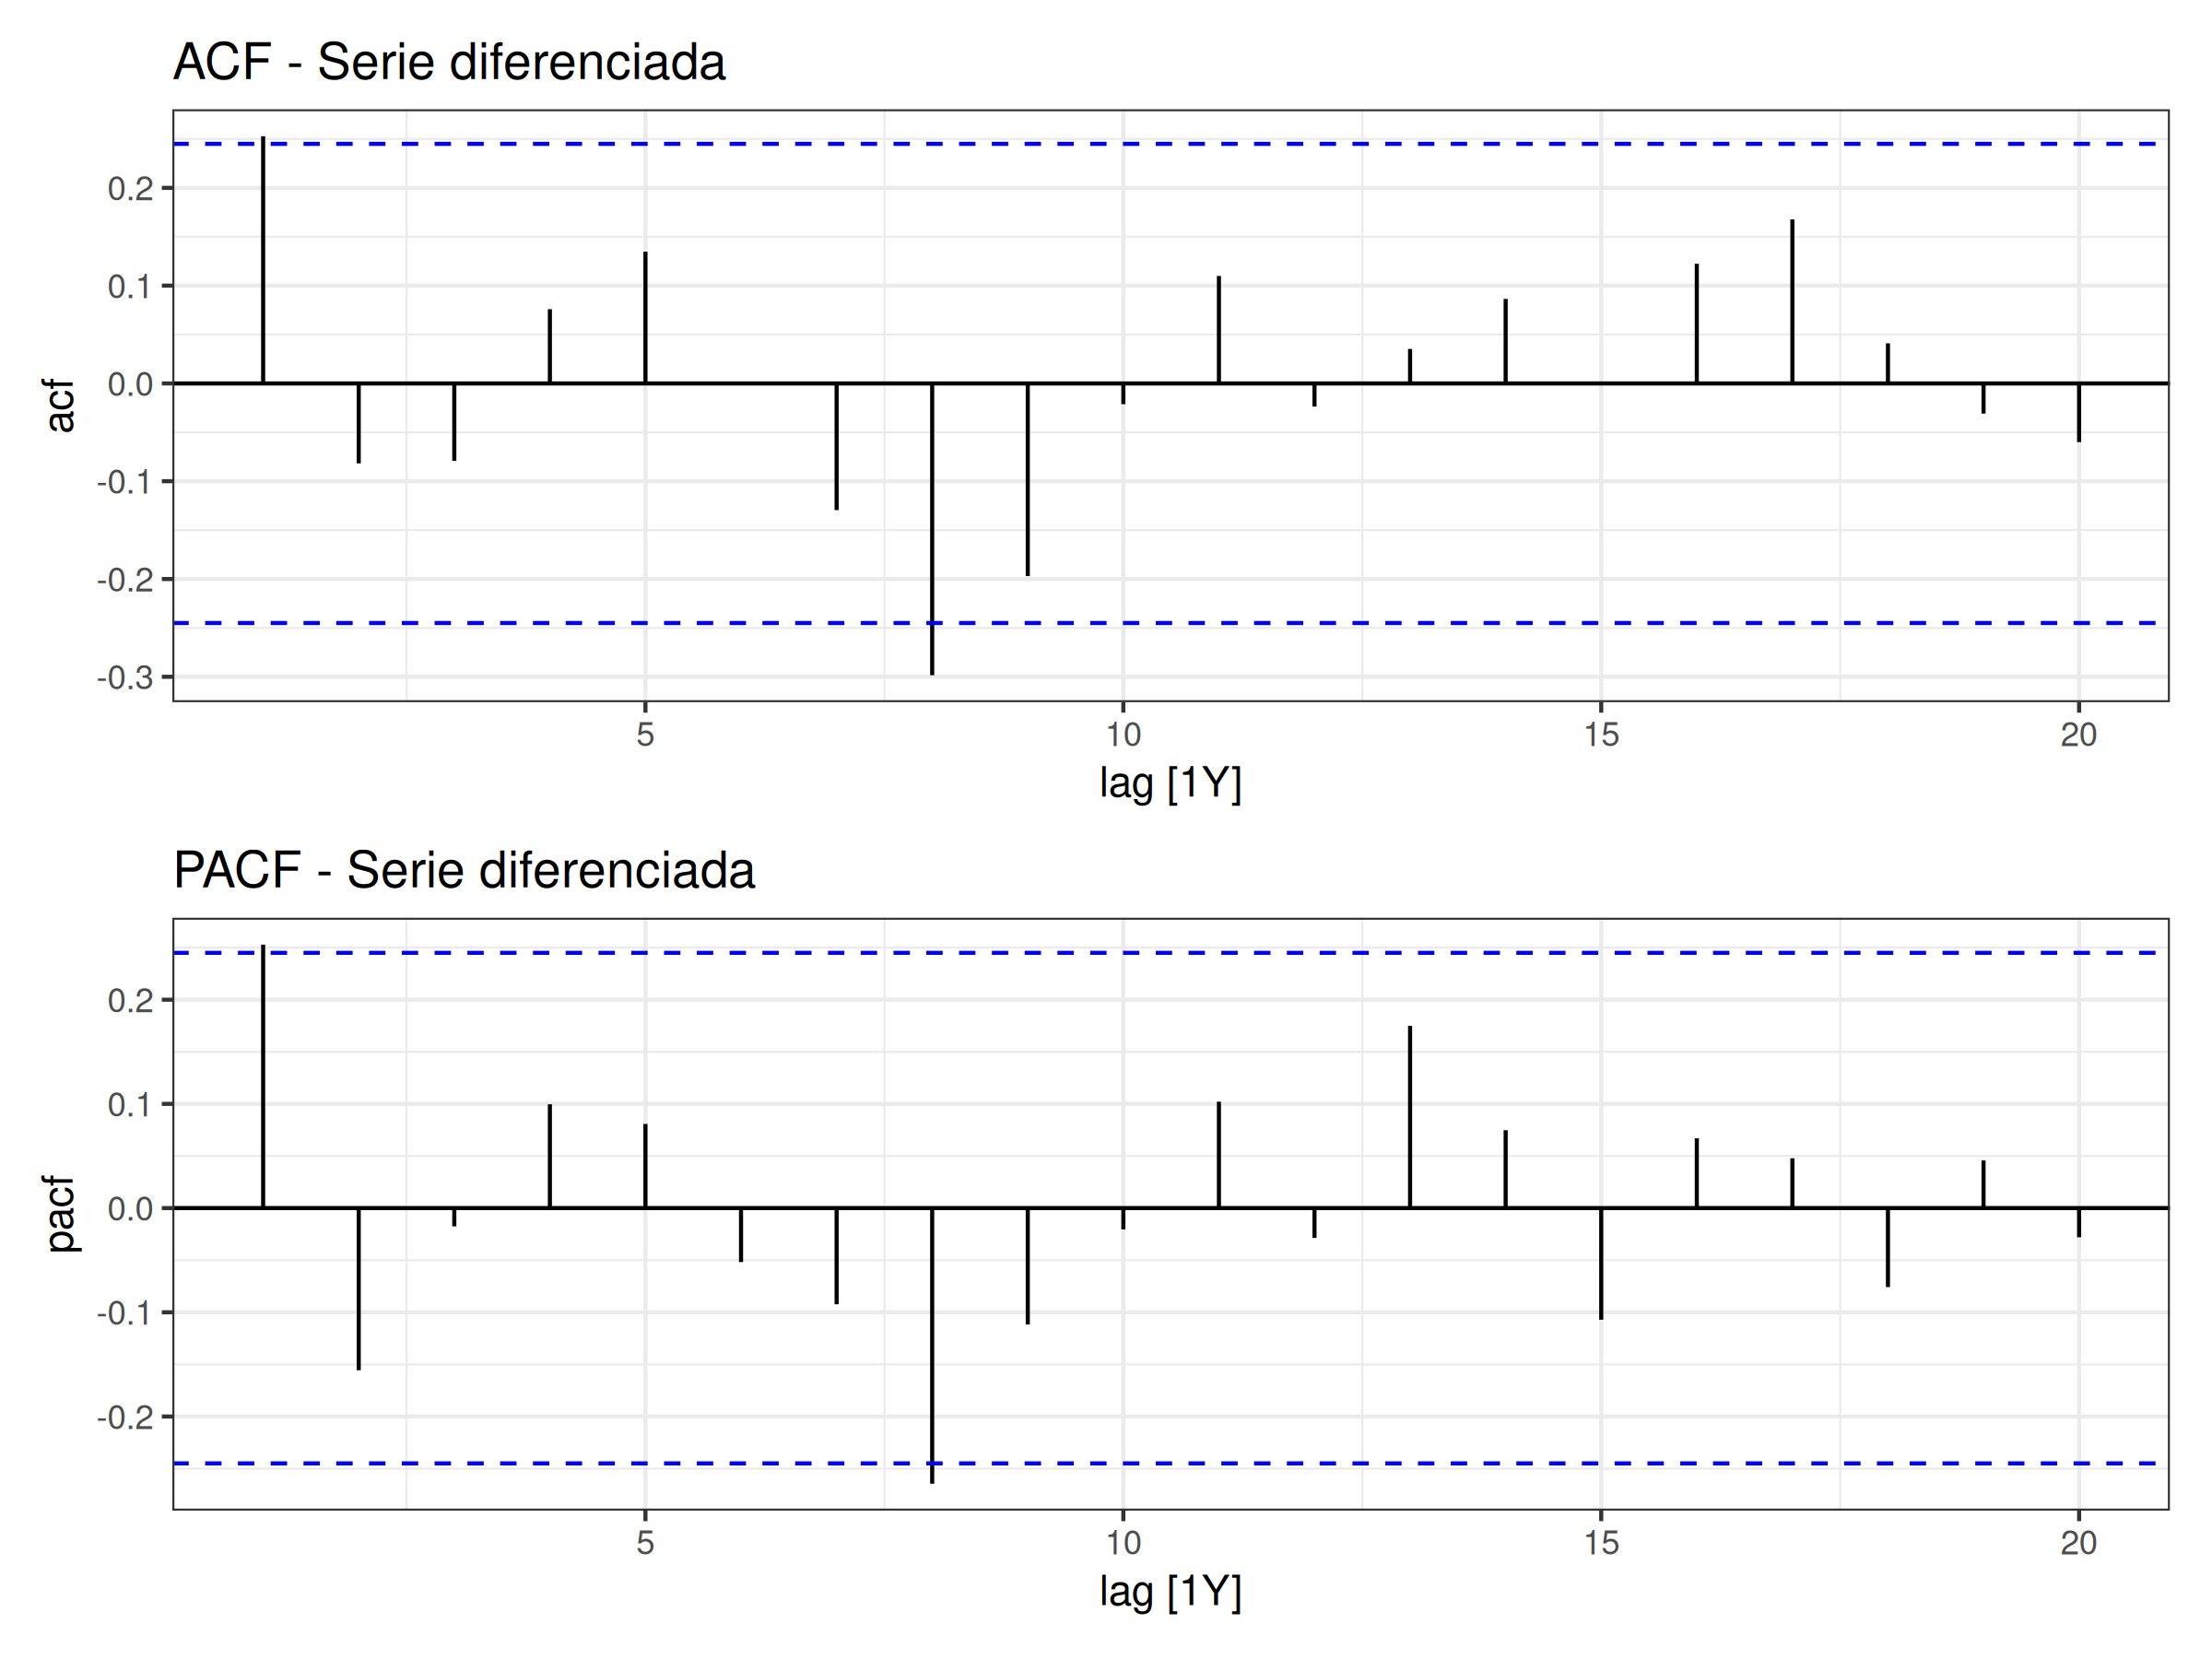

In [8]:
# Graficar la funcion de ACF y PACF de la serie diferenciada
graficar_autocorrelacion(pib_col, pib_diff, titulo = "Serie diferenciada")

In [9]:
# Test estacionariedad de la serie diferenciada y del crecimiento
bind_rows(
  test_estacionariedad(pib_col$pib_diff)    |> mutate(Serie = "Primera diferencia", .before = 1),
  test_estacionariedad(pib_col$crecimiento) |> mutate(Serie = "Crecimiento (log-diferencia)", .before = 1)
)

Serie,Test,Estadistico,P-valor,Estacionario
<chr>,<chr>,<dbl>,<dbl>,<chr>
Primera diferencia,Prueba Augmented Dickey-Fuller (ADF),-3.4317,0.0589,No
Primera diferencia,Prueba KPSS,0.2410,0.1000,Sí
Crecimiento (log-diferencia),Prueba Augmented Dickey-Fuller (ADF),-3.0425,0.1528,No
Crecimiento (log-diferencia),Prueba KPSS,0.1457,0.1000,Sí


**Interpretación**

- Después de diferenciar, la KPSS ya no rechaza la estacionariedad y el ACF cae rápidamente a cero.
- La ADF queda en el límite (p-valor algo mayor a 0.05). En R, `tseries::adf.test()` incluye tendencia y un número fijo de rezagos, por lo que es más conservadora que `adfuller()` de Python; los resultados de ambos lenguajes no tienen que coincidir exactamente.
- Con la evidencia conjunta (KPSS y ACF) tratamos el crecimiento del PIB como una serie estacionaria: $\log(PIB_t) \sim I(1)$.

## Estimación modelos ARIMA

- Modelamos el crecimiento $\Delta \log(PIB_t)$, por lo que un $ARMA(p, q)$ sobre el crecimiento equivale a un $ARIMA(p, 1, q)$ sobre $\log(PIB_t)$.
- En `fable`, `pdq(p, d, q)` define la parte regular, `PDQ(0, 0, 0)` elimina la parte estacional y `1` incluye la constante.

In [10]:
pib_crecimiento <- pib_col |>
  filter(!is.na(crecimiento))

modelos <- pib_crecimiento |>
  model(
    `ARIMA(1, 1, 0)` = ARIMA(crecimiento ~ 1 + pdq(1, 0, 0) + PDQ(0, 0, 0)),
    `ARIMA(0, 1, 1)` = ARIMA(crecimiento ~ 1 + pdq(0, 0, 1) + PDQ(0, 0, 0)),
    `ARIMA(1, 1, 1)` = ARIMA(crecimiento ~ 1 + pdq(1, 0, 1) + PDQ(0, 0, 0)),
    # Auto-ARIMA encuentra los parámetros óptimos automáticamente (búsqueda exhaustiva)
    `auto-ARIMA`     = ARIMA(crecimiento ~ pdq(d = 0) + PDQ(0, 0, 0),
                             stepwise = FALSE, approximation = FALSE)
  )

modelos

"ARIMA(1, 1, 0)","ARIMA(0, 1, 1)","ARIMA(1, 1, 1)",auto-ARIMA
<model>,<model>,<model>,<model>
"<ARIMA(1,0,0) w/ mean>","<ARIMA(0,0,1) w/ mean>","<ARIMA(1,0,1) w/ mean>","<ARIMA(1,0,0) w/ mean>"


In [11]:
# ARIMA(1, 1, 0)
modelos |> select(`ARIMA(1, 1, 0)`) |> report()

Series: crecimiento 
Model: ARIMA(1,0,0) w/ mean 

Coefficients:
         ar1  constant
      0.2796    0.0517
s.e.  0.1199    0.0125

sigma^2 estimated as 0.01037:  log likelihood=55.51
AIC=-105.02   AICc=-104.61   BIC=-98.59


In [12]:
# ARIMA(0, 1, 1)
modelos |> select(`ARIMA(0, 1, 1)`) |> report()

Series: crecimiento 
Model: ARIMA(0,0,1) w/ mean 

Coefficients:
         ma1  constant
      0.2576    0.0717
s.e.  0.1170    0.0159

sigma^2 estimated as 0.01047:  log likelihood=55.22
AIC=-104.43   AICc=-104.02   BIC=-98


In [13]:
# ARIMA(1, 1, 1)
modelos |> select(`ARIMA(1, 1, 1)`) |> report()

Series: crecimiento 
Model: ARIMA(1,0,1) w/ mean 

Coefficients:
         ar1      ma1  constant
      0.5698  -0.3200    0.0309
s.e.  0.2828   0.3219    0.0084

sigma^2 estimated as 0.01045:  log likelihood=55.76
AIC=-103.52   AICc=-102.83   BIC=-94.94


In [14]:
# Auto-ARIMA
modelos |> select(`auto-ARIMA`) |> report()

Series: crecimiento 
Model: ARIMA(1,0,0) w/ mean 

Coefficients:
         ar1  constant
      0.2796    0.0517
s.e.  0.1199    0.0125

sigma^2 estimated as 0.01037:  log likelihood=55.51
AIC=-105.02   AICc=-104.61   BIC=-98.59


In [15]:
comparar_modelos_arima <- function(modelos) {
  glance(modelos) |>
    select(Modelo = .model, AIC, AICc, BIC, `Log-Lik` = log_lik, sigma2) |>
    left_join(
      accuracy(modelos) |> select(Modelo = .model, RMSE, MAE),
      by = "Modelo"
    ) |>
    arrange(AICc) |>
    mutate(Ranking = row_number(), .before = 1)
}

tabla_modelos <- comparar_modelos_arima(modelos)
tabla_modelos

cat("Mejor modelo (menor AICc):", tabla_modelos$Modelo[1], " →  AICc:", tabla_modelos$AICc[1], "\n")

Ranking,Modelo,AIC,AICc,BIC,Log-Lik,sigma2,RMSE,MAE
<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,"ARIMA(1, 1, 0)",-105.0153,-104.6086,-98.58593,55.50767,0.01036774,0.10019284,0.07848828
2,auto-ARIMA,-105.0153,-104.6086,-98.58593,55.50767,0.01036774,0.10019284,0.07848828
3,"ARIMA(0, 1, 1)",-104.4317,-104.0249,-98.00225,55.21583,0.01046635,0.10066821,0.07882825
4,"ARIMA(1, 1, 1)",-103.5167,-102.8270,-94.94416,55.75835,0.01045423,0.09978181,0.07841059


Mejor modelo (menor AICc): ARIMA(1, 1, 0)  →  AICc: -104.6086 


In [16]:
# Seleccionar el mejor modelo según el AICc
# (el auto-ARIMA llega al mismo ARIMA(1, 1, 0))
mejor_modelo <- modelos |> select(all_of(tabla_modelos$Modelo[1]))
report(mejor_modelo)

Series: crecimiento 
Model: ARIMA(1,0,0) w/ mean 

Coefficients:
         ar1  constant
      0.2796    0.0517
s.e.  0.1199    0.0125

sigma^2 estimated as 0.01037:  log likelihood=55.51
AIC=-105.02   AICc=-104.61   BIC=-98.59


**Interpretación del mejor modelo**

$$
\Delta \log(PIB_t) = 0.0517 + 0.2796\, \Delta \log(PIB_{t-1}) + \varepsilon_t, \qquad \varepsilon_t \sim WN(0,\ 0.0104)
$$

- $\phi_1 = 0.28$: un 28% del crecimiento del año anterior se transmite al crecimiento de este año.
- La media de largo plazo del crecimiento es $0.0517 / (1 - 0.2796) \approx 7.2\%$ anual (PIB en dólares corrientes).
- El auto-ARIMA selecciona el mismo modelo, que además tiene el menor AICc.

## Diagnóstico del mejor modelo

Test,Estadistico,P-valor,Conclusion
<chr>,<dbl>,<dbl>,<chr>
Durbin-Watson,2.0237,NA,Sin autocorrelación
Ljung-Box (hasta lag 20),26.6325,0.0637,Sin autocorrelación


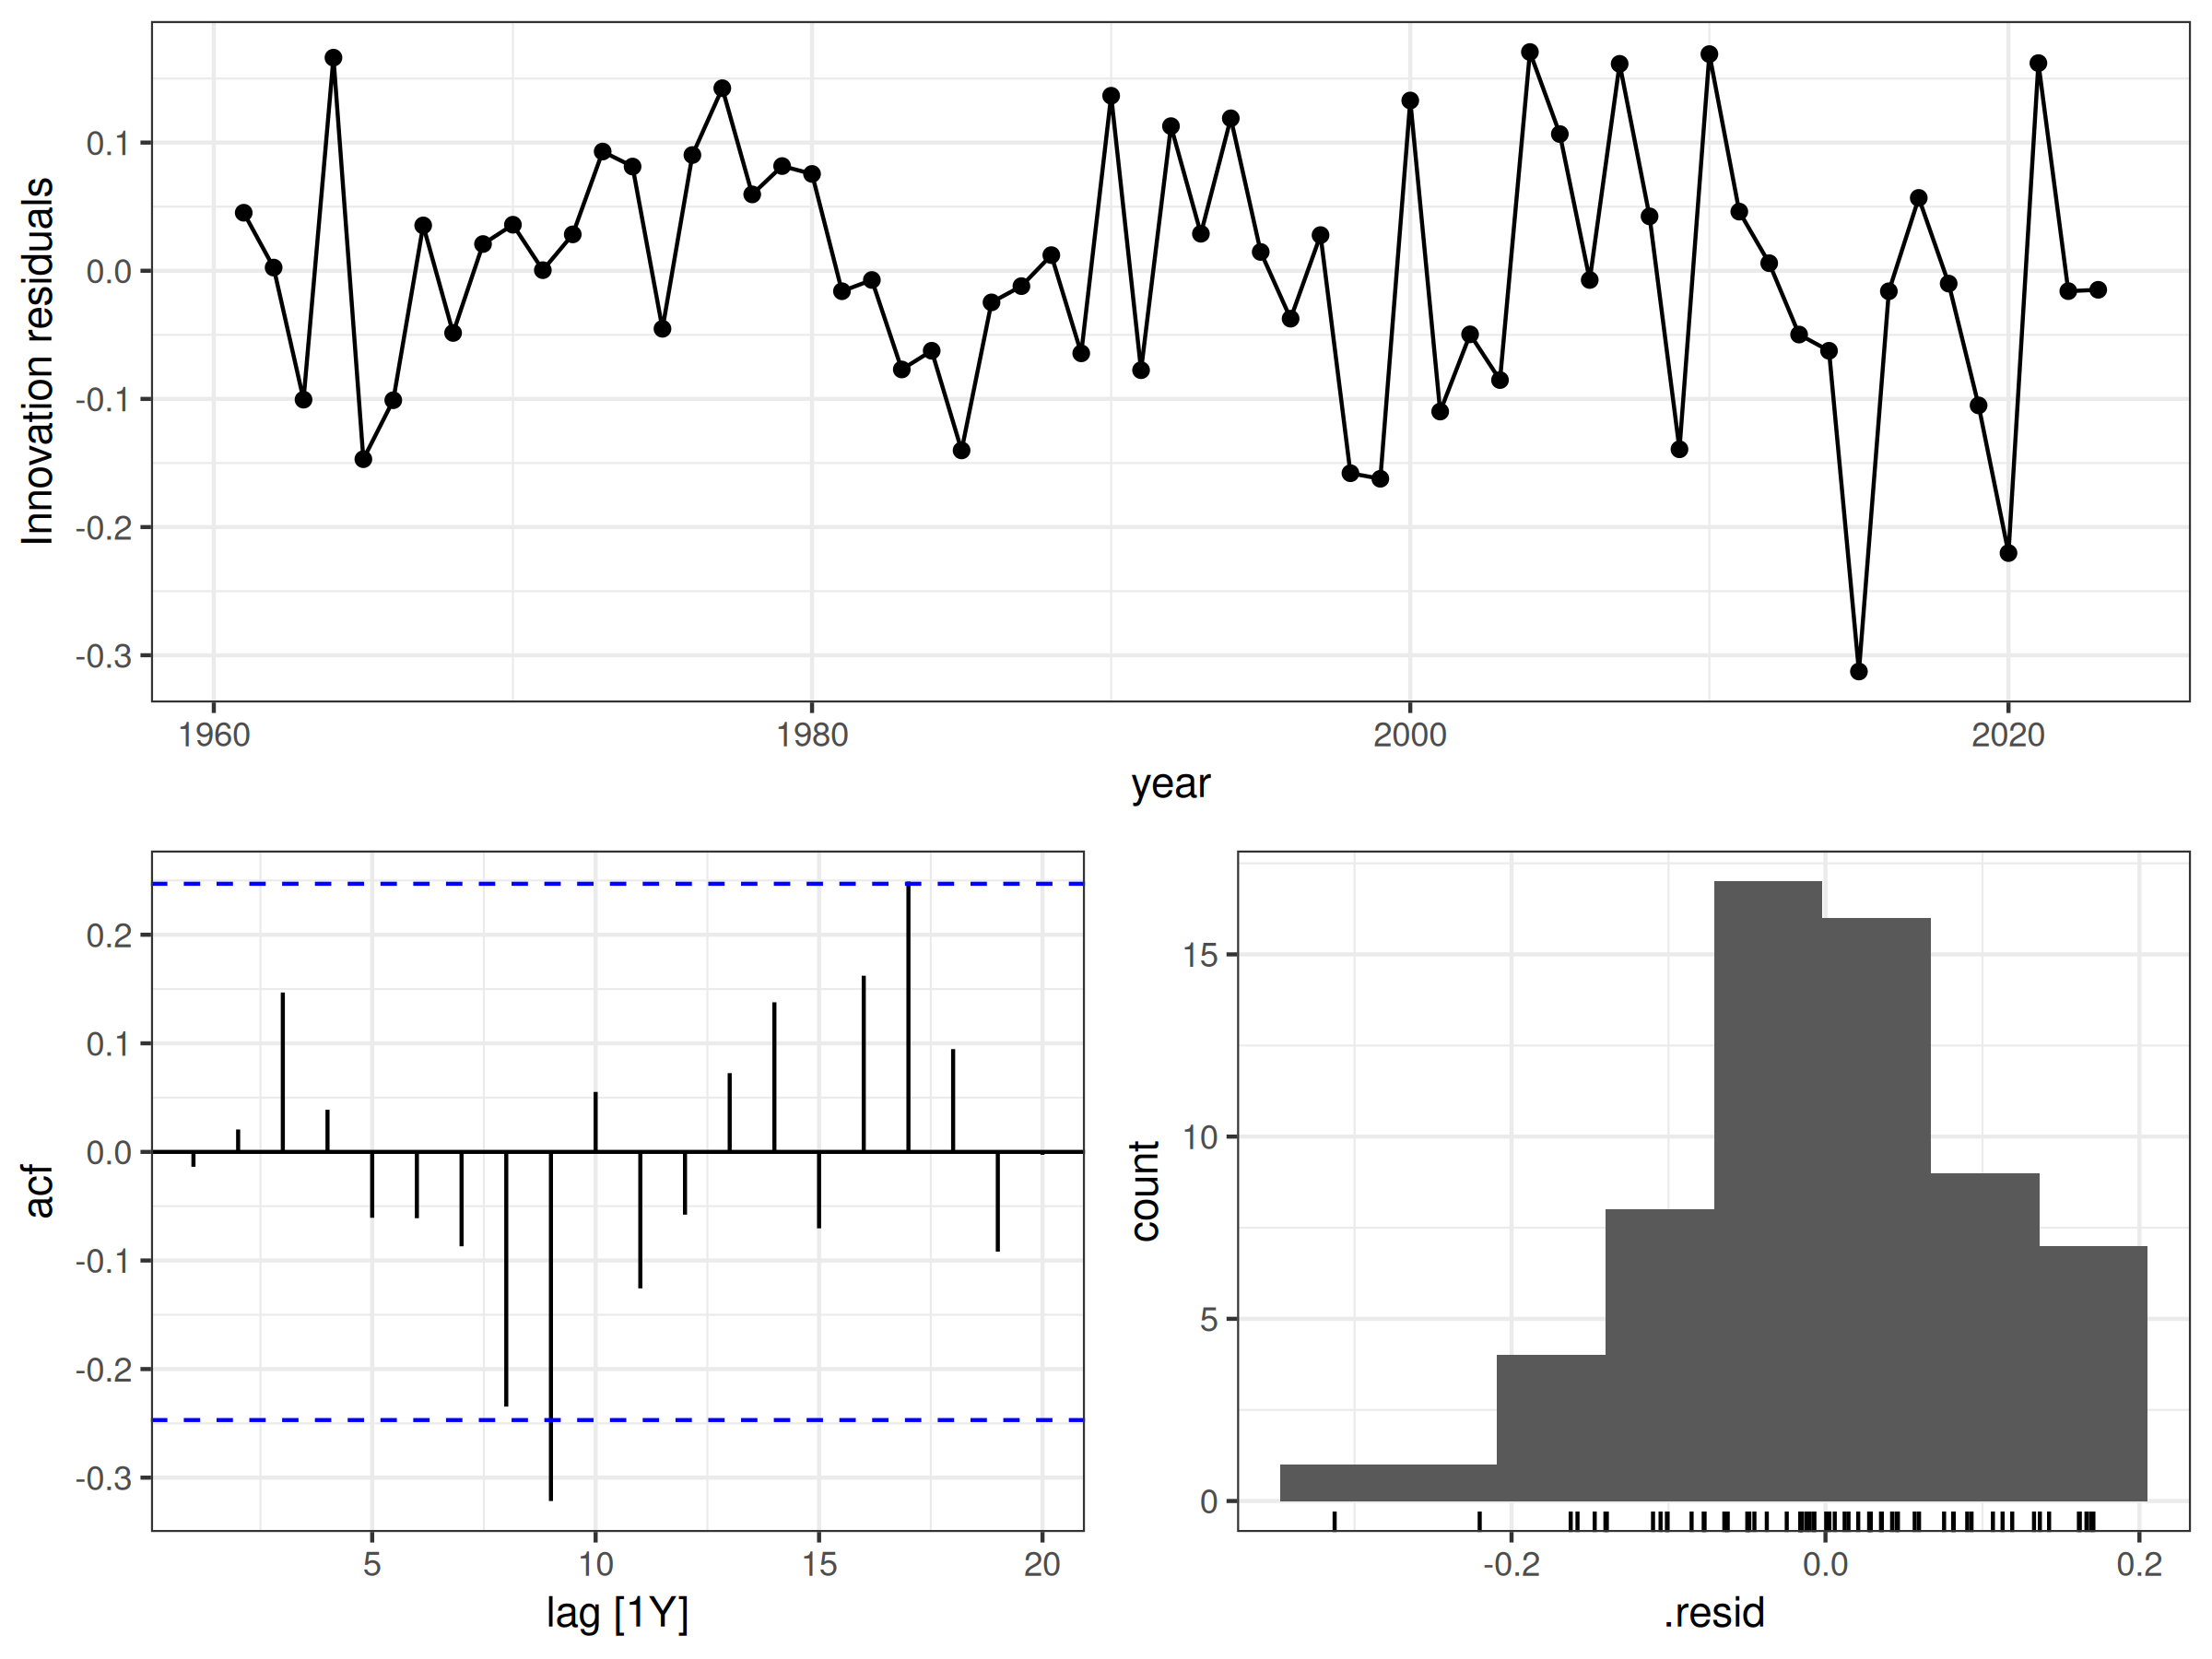

In [17]:
# Verificar ruido blanco: residuos en el tiempo, ACF e histograma
mejor_modelo |> gg_tsresiduals(lag_max = 20)

# Pruebas de autocorrelación de los residuos
residuos <- augment(mejor_modelo)$.innov
test_autocorrelacion(residuos, n_lags = 20)

test,estadistico,p_valor
<chr>,<dbl>,<dbl>
Shapiro-Wilk,0.9770,0.2843
Jarque-Bera,1.9846,0.3707
Kolmogorov-Smirnov,0.0729,0.8670
Asimetría,-0.4130,NA
Curtosis,3.2716,NA


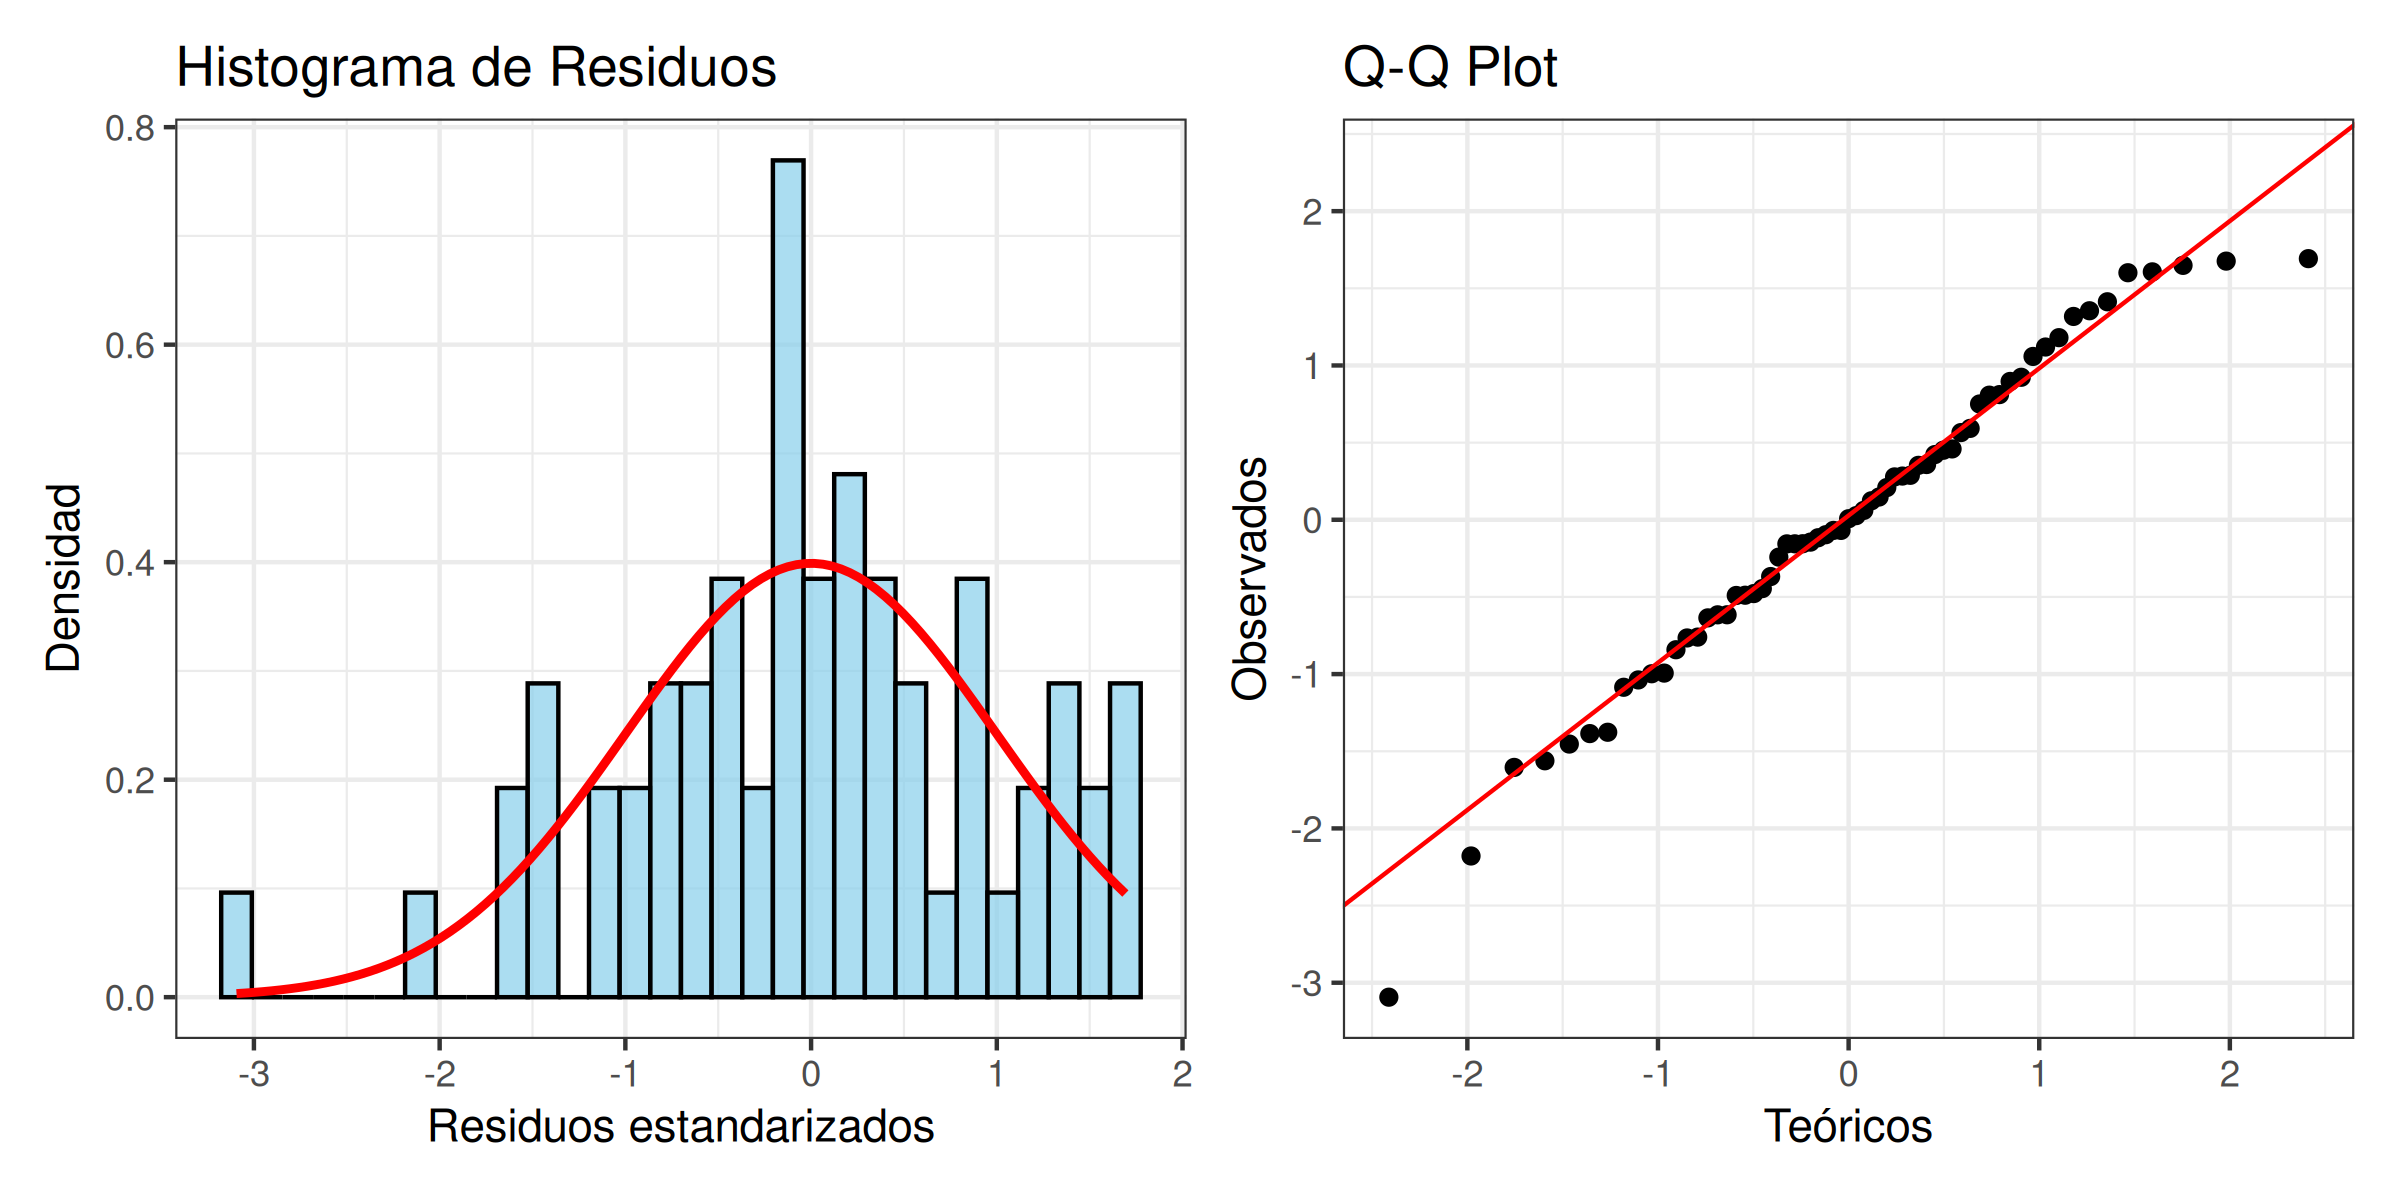

In [18]:
# Normalidad de los residuos
check_normalidad <- function(resid) {
  resid     <- as.numeric(na.omit(resid))
  resid_std <- as.numeric(scale(resid))

  # Gráfico 1: Histograma con curva normal
  p1 <- tibble(res = resid_std) |>
    ggplot(aes(x = res)) +
    geom_histogram(aes(y = after_stat(density)), bins = 30,
                   fill = "skyblue", color = "black", alpha = 0.7) +
    stat_function(fun = dnorm, args = list(mean = 0, sd = 1),
                  color = "red", linewidth = 1) +
    labs(title = "Histograma de Residuos", x = "Residuos estandarizados", y = "Densidad")

  # Gráfico 2: Q-Q Plot
  p2 <- tibble(res = resid_std) |>
    ggplot(aes(sample = res)) +
    stat_qq() +
    stat_qq_line(color = "red") +
    labs(title = "Q-Q Plot", x = "Teóricos", y = "Observados")

  print(p1 | p2)

  sw <- shapiro.test(resid)              # Shapiro-Wilk
  jb <- jarque.bera.test(resid)          # Jarque-Bera
  ks <- ks.test(resid_std, "pnorm")      # Kolmogorov-Smirnov

  tibble(
    test        = c("Shapiro-Wilk", "Jarque-Bera", "Kolmogorov-Smirnov", "Asimetría", "Curtosis"),
    estadistico = round(c(sw$statistic, jb$statistic, ks$statistic,
                          skewness(resid), kurtosis(resid)), 4),
    p_valor     = round(c(sw$p.value, jb$p.value, ks$p.value, NA, NA), 4)
  )
}

options(repr.plot.height = 4)
check_normalidad(residuos)

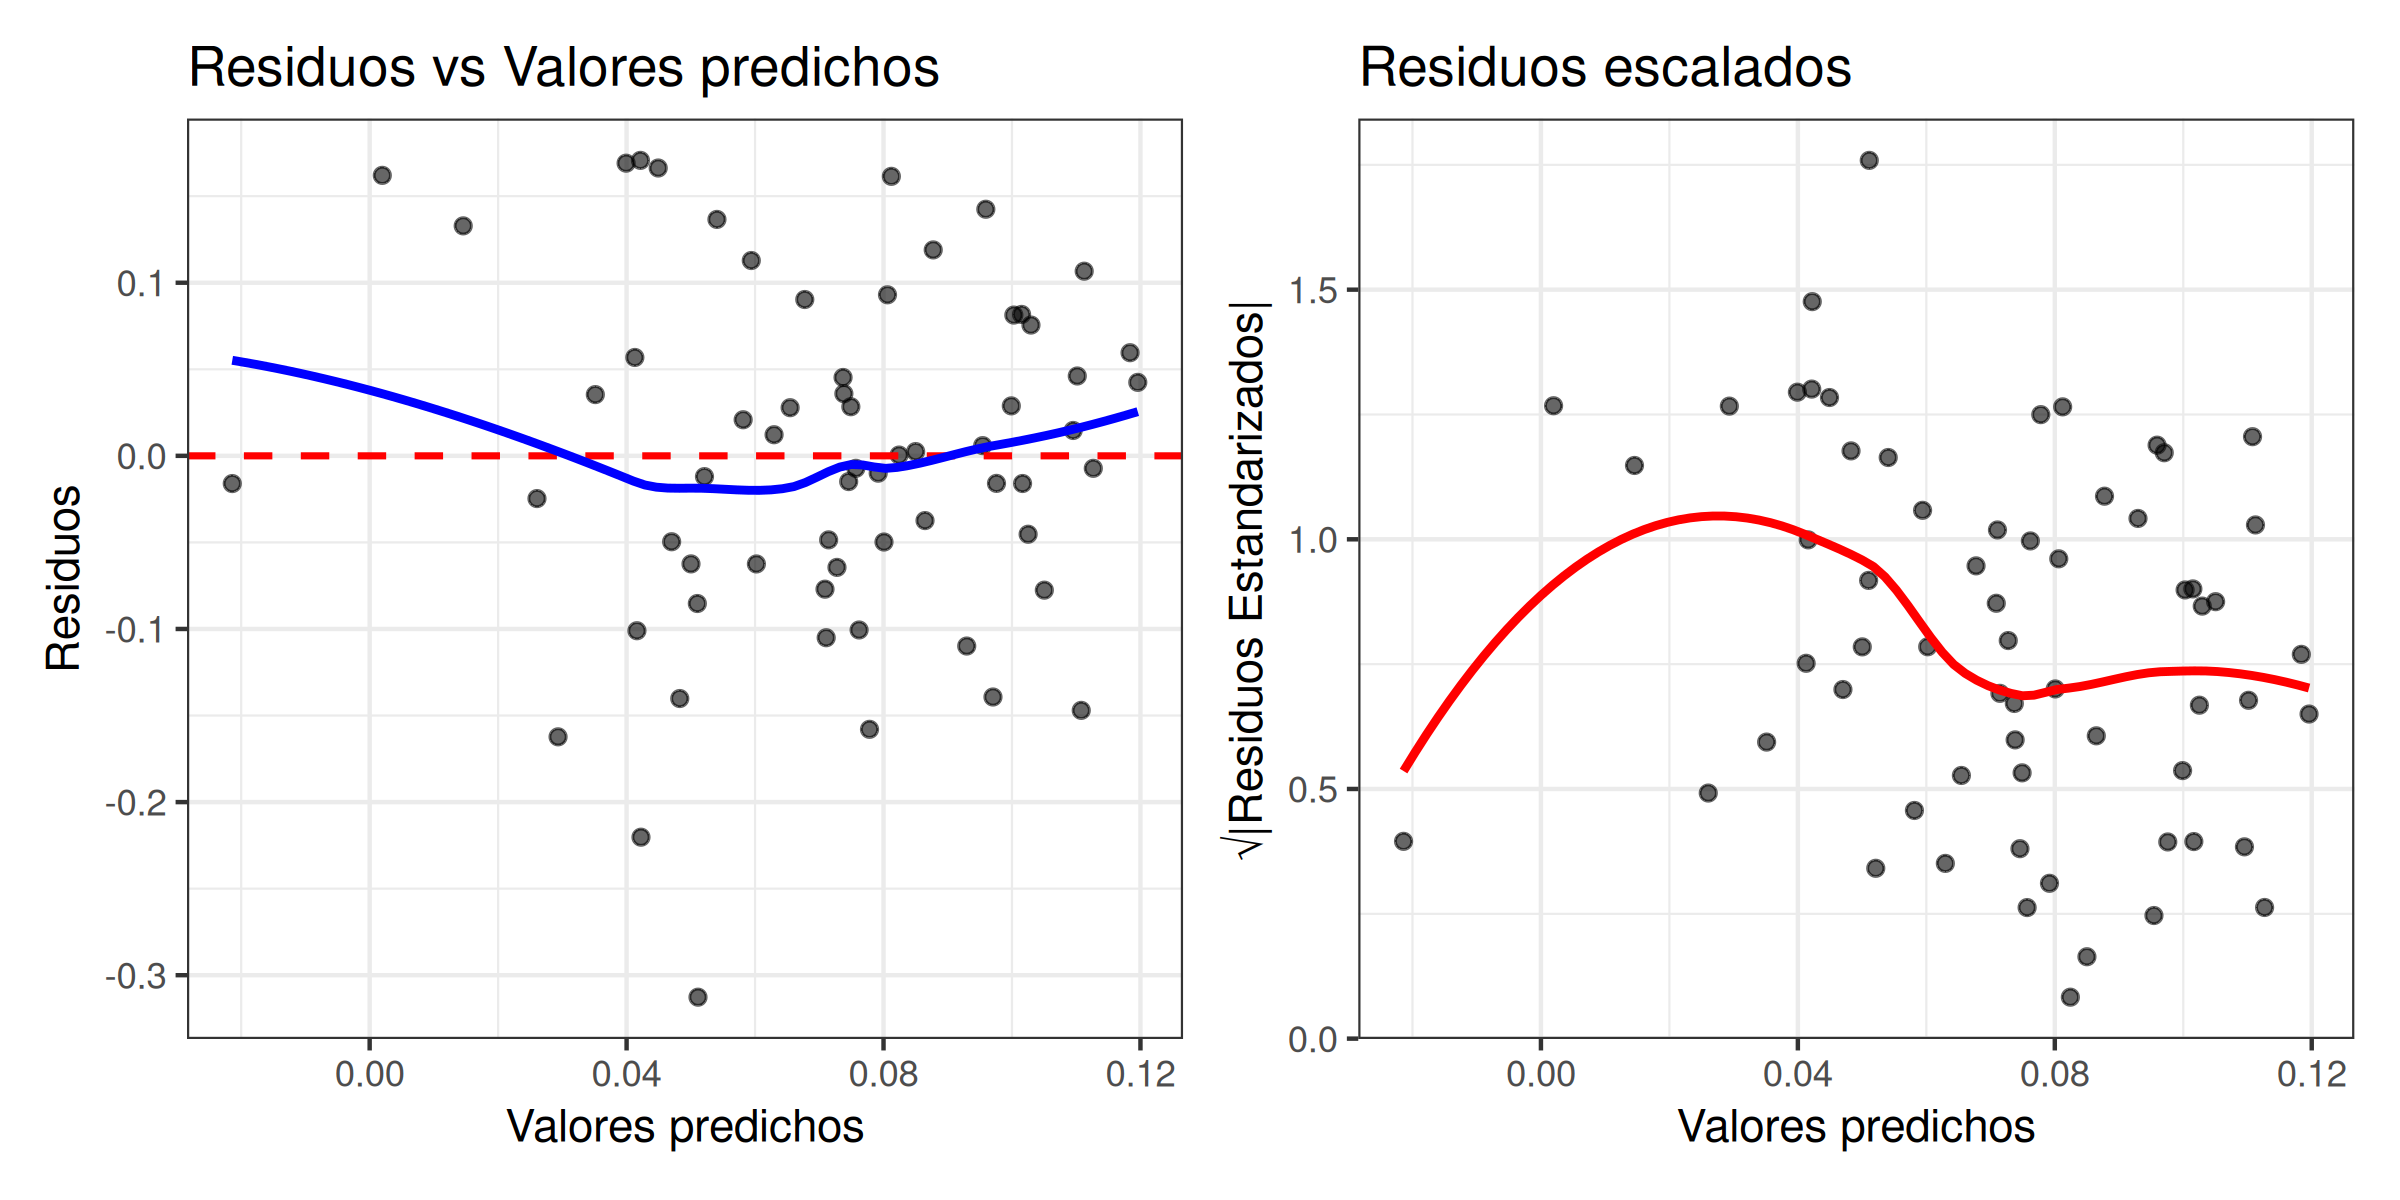

In [19]:
# Homocedasticidad de los residuos
check_homocedasticidad <- function(modelo) {
  datos <- augment(modelo) |>
    as_tibble() |>
    filter(!is.na(.innov)) |>
    mutate(resid_sqrt = sqrt(abs(as.numeric(scale(.innov)))))

  # Gráfico 1: Residuos vs Valores ajustados
  p1 <- datos |>
    ggplot(aes(x = .fitted, y = .innov)) +
    geom_point(alpha = 0.6) +
    geom_hline(yintercept = 0, colour = "red", linetype = "dashed", linewidth = 0.8) +
    geom_smooth(method = "loess", formula = y ~ x, se = FALSE, colour = "blue") +
    labs(title = "Residuos vs Valores predichos", x = "Valores predichos", y = "Residuos")

  # Gráfico 2: Residuos escalados
  p2 <- datos |>
    ggplot(aes(x = .fitted, y = resid_sqrt)) +
    geom_point(alpha = 0.6) +
    geom_smooth(method = "loess", formula = y ~ x, se = FALSE, colour = "red") +
    labs(title = "Residuos escalados", x = "Valores predichos",
         y = "√|Residuos Estandarizados|")

  p1 | p2
}

check_homocedasticidad(mejor_modelo)
options(repr.plot.height = 6)

**Interpretación**

- Los residuos se comportan como ruido blanco: Durbin-Watson ≈ 2 y Ljung-Box no rechaza la ausencia de autocorrelación hasta el rezago 20.
- No se rechaza la normalidad de los residuos (Shapiro-Wilk, Jarque-Bera y Kolmogorov-Smirnov con p-valor > 0.05).
- Los residuos no muestran un patrón claro frente a los valores ajustados, aunque hay algunos valores extremos (crisis). El modelo es válido para pronosticar.

## Pronóstico mejor modelo modelo crecimiento PIB

Acorde al DANE En 2024p, el Producto Interno Bruto (PIB) presenta un crecimiento de 1,5% respecto a 2023.
https://www.dane.gov.co/index.php/estadisticas-por-tema/cuentas-nacionales/cuentas-nacionales-anuales

> Nota: el modelo se estima con el PIB en dólares corrientes, por lo que su crecimiento incluye el efecto de la inflación y de la tasa de cambio; no es directamente comparable con el crecimiento real que reporta el DANE.

Año,Pronóstico,IC Inferior,IC Superior
<dbl>,<dbl>,<dbl>,<dbl>
2024,0.06843640,-0.1311313,0.2680041
2025,0.07087384,-0.1363460,0.2780936
2026,0.07155526,-0.1362507,0.2793613
2027,0.07174577,-0.1361060,0.2795975
2028,0.07179903,-0.1360563,0.2796544


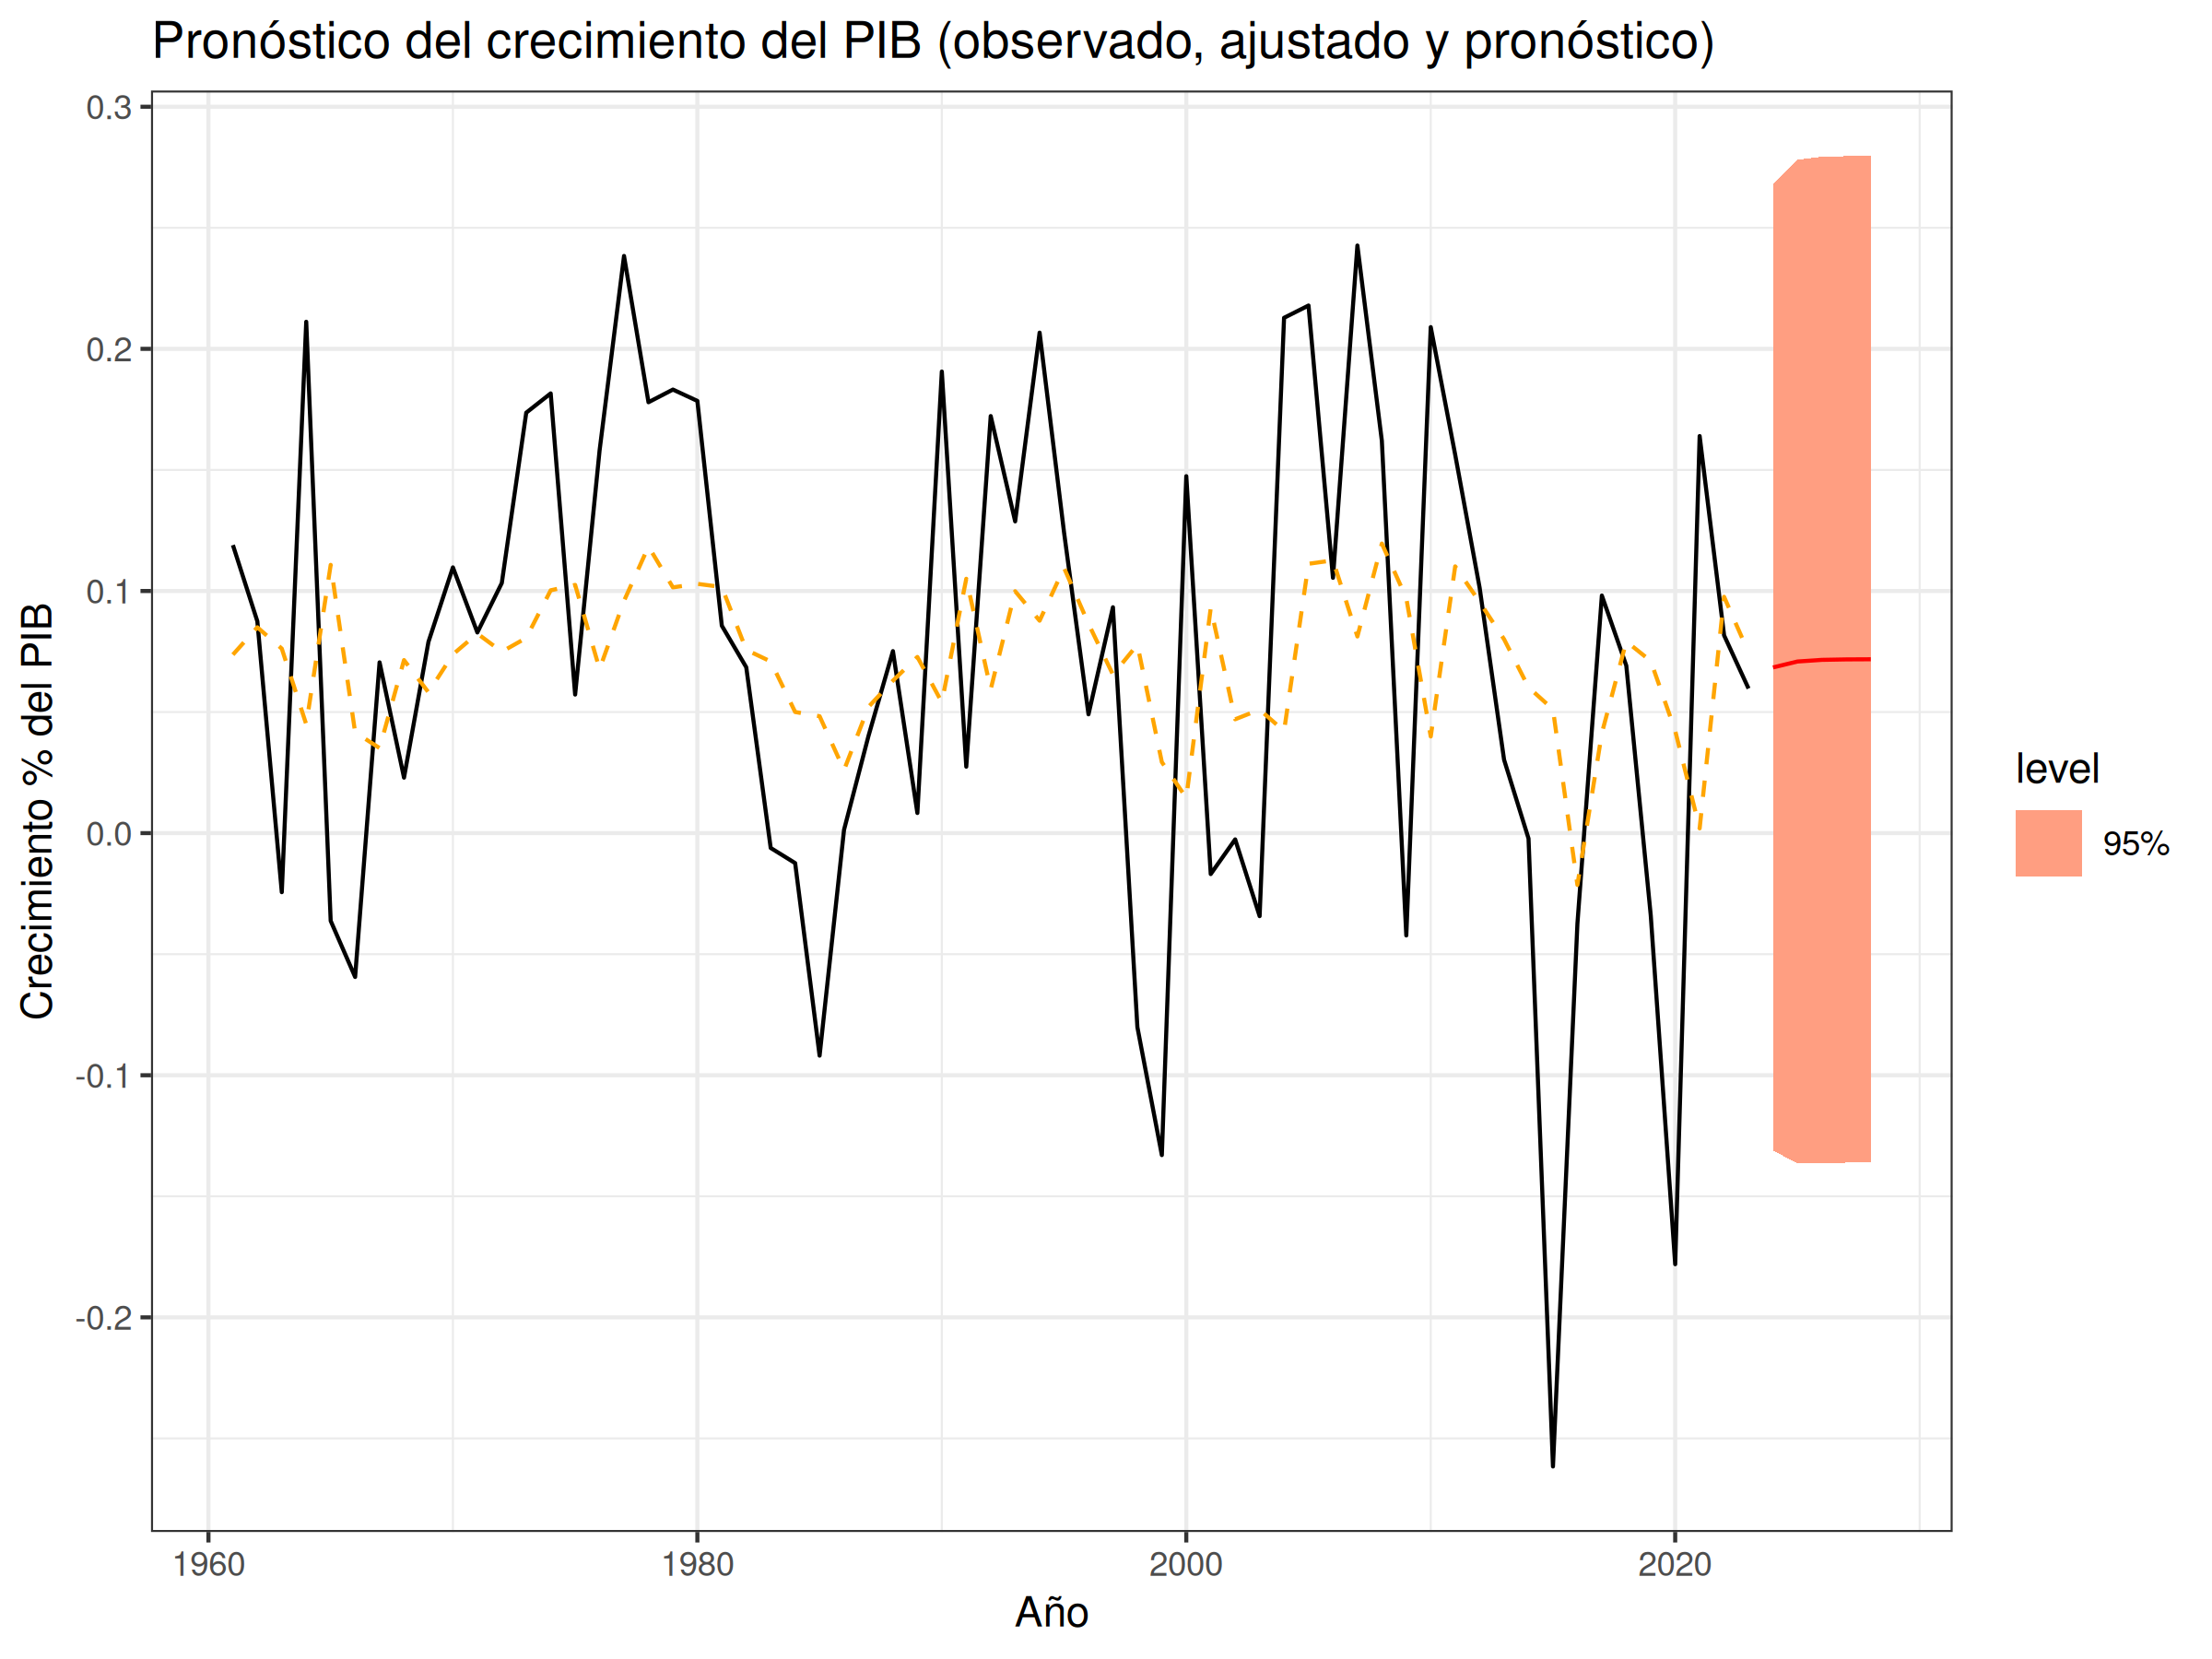

In [20]:
# Pronostico de los proximos 5 años
t_pronostico <- 5

pronostico_pib <- mejor_modelo |>
  forecast(h = t_pronostico)

# Graficar resultados pronostico
pronostico_pib |>
  autoplot(pib_crecimiento, level = 95, colour = "red", linetype = "dashed") +
  autolayer(fitted(mejor_modelo), .fitted, colour = "orange", linetype = "dashed") +
  labs(x = "Año", y = "Crecimiento % del PIB",
       title = "Pronóstico del crecimiento del PIB (observado, ajustado y pronóstico)")

# Tabla de pronóstico
pronostico_pib |>
  hilo(level = 95) |>
  unpack_hilo(`95%`) |>
  as_tibble() |>
  select(Año = year, `Pronóstico` = .mean, `IC Inferior` = `95%_lower`, `IC Superior` = `95%_upper`)

## Pronostico en sus niveles del PIB

- Reversar la transformación logarítmica del crecimiento
$$
\Delta \log(PIB_t) = \log(PIB_t) - \log(PIB_{t-1})  \\
PIB_{t+h} = PIB_{t} \cdot \exp\left(\sum^{h}_{i=1}\Delta \log(PIB_{t+i})\right)
$$

- En `fable` no es necesario hacerlo a mano: si se especifica el modelo sobre `log(pib)` con `d = 1`, el paquete estima el mismo modelo y revierte la transformación automáticamente (media e intervalos de predicción en dólares).

Series: pib 
Model: ARIMA(1,1,0) w/ drift 
Transformation: log(pib) 

Coefficients:
         ar1  constant
      0.2796    0.0517
s.e.  0.1199    0.0125

sigma^2 estimated as 0.01038:  log likelihood=55.51
AIC=-105.02   AICc=-104.61   BIC=-98.59


Año,Pronóstico,IC Inferior,IC Superior
<dbl>,<dbl>,<dbl>,<dbl>
2024,394928394869,321785702041,479706404573
2025,427516462452,304961756359,583252930045
2026,463560978975,296888799804,691290232252
2027,502847339139,293909961890,806041352239
2028,545488237646,294180138011,929655273141


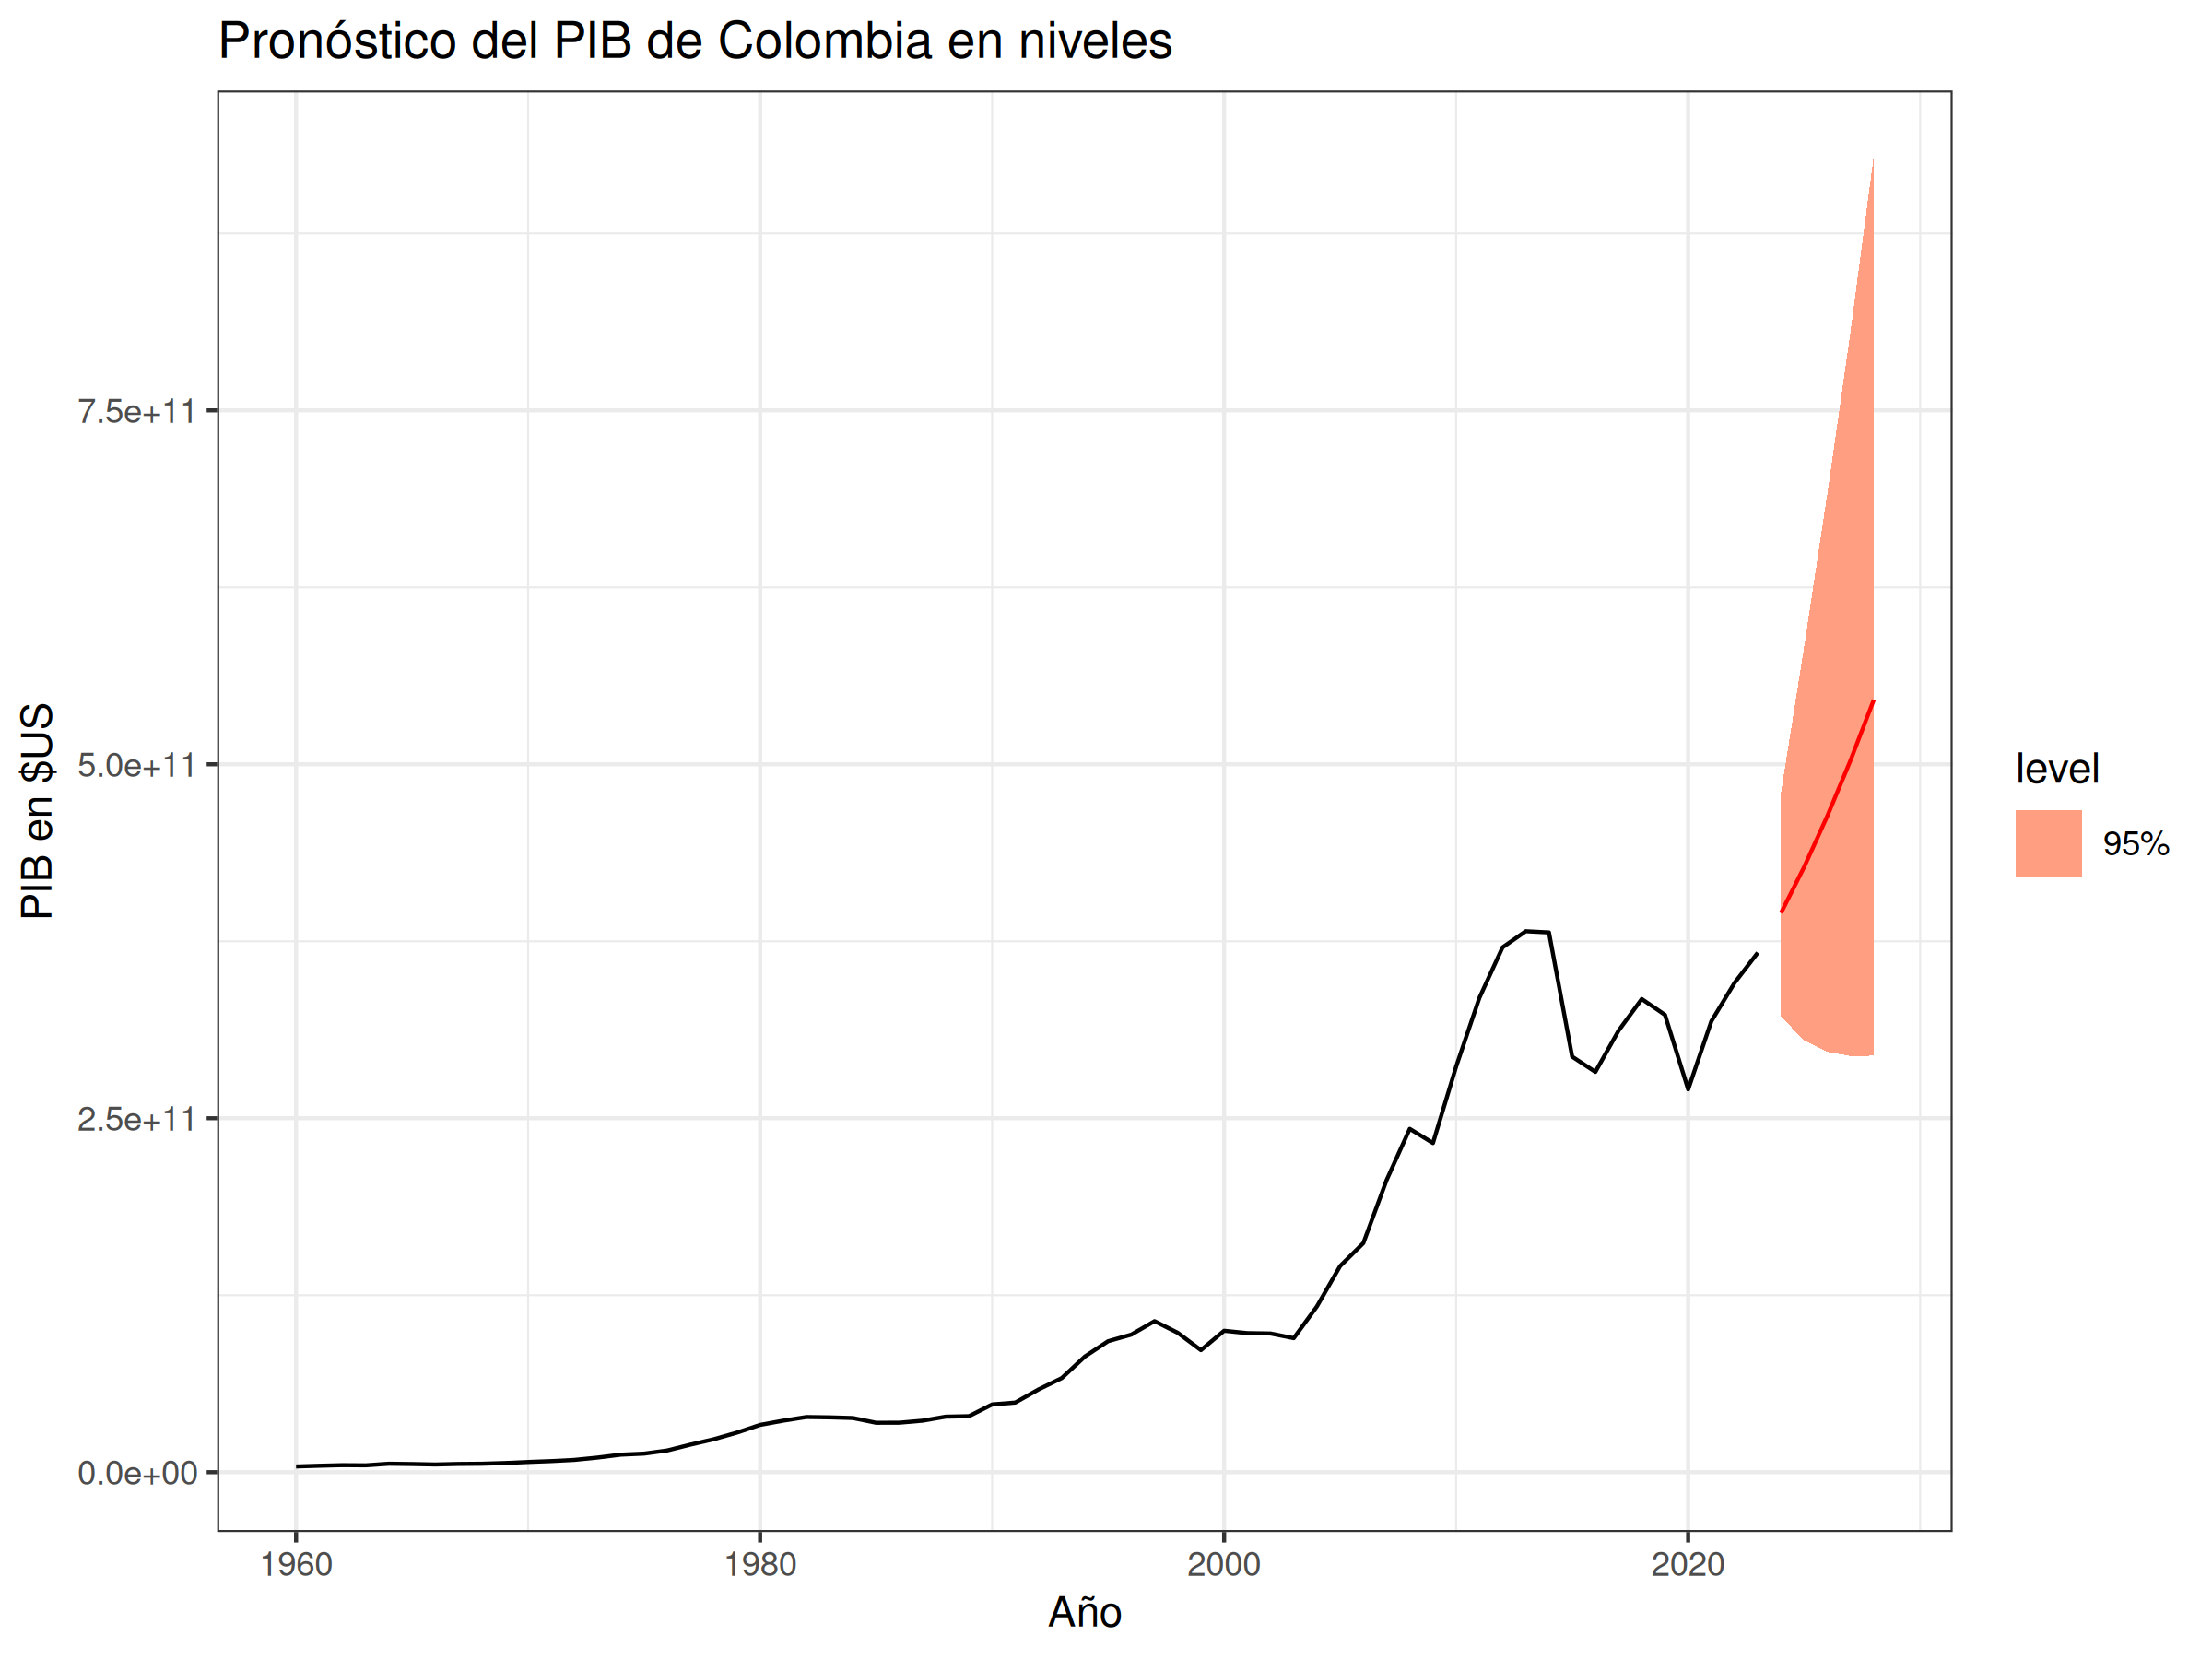

In [21]:
# Mismo orden (p, q) del mejor modelo, ahora sobre log(PIB) con una diferencia
orden <- mejor_modelo[[1]][[1]]$fit$spec

modelo_niveles <- pib_col |>
  model(
    ARIMA(log(pib) ~ 1 + pdq(orden$p, 1, orden$q) + PDQ(0, 0, 0))
  )
report(modelo_niveles)

pronostico_niveles <- modelo_niveles |>
  forecast(h = t_pronostico)

# Graficar resultados pronostico
pronostico_niveles |>
  autoplot(pib_col, level = 95, colour = "red", linetype = "dashed") +
  labs(x = "Año", y = "PIB en $US", title = "Pronóstico del PIB de Colombia en niveles")

# Tabla de pronóstico en niveles
pronostico_niveles |>
  hilo(level = 95) |>
  unpack_hilo(`95%`) |>
  as_tibble() |>
  select(Año = year, `Pronóstico` = .mean, `IC Inferior` = `95%_lower`, `IC Superior` = `95%_upper`)